# Projet Data Science et commerce international

**Binôme :** AHNNAOU YOUNESS / AIT BOUSALEM ISRAA   

**Projet :** 36 : Performance logistique des pays

**Date :** 15/11/2026

# **1. Problématique et hypothèses**

**Problématique** :


Comment les pays peuvent-ils être regroupés en fonction des six composantes de leur performance logistique, selon les données du Logistics Performance Index (LPI) 2023 ?

**Objectif :**

Identifier des groupes de pays présentant des caractéristiques logistiques similaires à l'aide de méthodes de clustering non supervisé.

**Hypothèses** :

**H1** : Les pays ayant de bonnes infrastructures présentent généralement de meilleures performances logistiques.

**H2** : Les pays ayant des performances douanières similaires peuvent appartenir au même groupe.




## **1. Importation des bibliothèques (Libraries)**

Dans cette première étape, nous importons les bibliothèques Python nécessaires à la réalisation du projet.

- **Pandas** et **NumPy** seront utilisés pour la manipulation et le traitement des données.
- **Matplotlib** permettra de créer des visualisations.
- **Scikit-learn** fournira les outils nécessaires aux étapes de prétraitement et de Machine Learning, notamment la standardisation, le clustering et la réduction de dimensionnalité.
- **Random** et **os** permettront de gérer certains paramètres liés à la reproductibilité et à l'environnement d'exécution.

Nous fixons également une graine aléatoire (*random seed*) afin de rendre reproductibles les opérations aléatoires réalisées dans le notebook.

In [65]:
# Manipulation et traitement des données
import pandas as pd
import numpy as np

# Visualisation des données
import matplotlib.pyplot as plt

# Machine Learning et prétraitement
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Reproductibilité et environnement
import random
import os
import warnings

# Ignorer les avertissements non essentiels
warnings.filterwarnings("ignore")

# Fixer la graine aléatoire pour la reproductibilité
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Paramètres d'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

# Afficher les versions des principales bibliothèques
print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)

print("\nBibliothèques importées avec succès.")

Pandas : 2.2.3
NumPy : 2.4.6
Scikit-learn : 1.6.1

Bibliothèques importées avec succès.


In [66]:

# ==========================================
# AUTOMATIC EXPORT OF ALL PROJECT FIGURES
# ==========================================

import os
import matplotlib.pyplot as plt

# Create a folder to store all figures
os.makedirs("/content/figures", exist_ok=True)

# Keep the original display function
original_show = plt.show

# Counter for exported figures
figure_counter = 0

# Save every figure automatically before displaying it
def save_and_show(*args, **kwargs):
    global figure_counter

    for fig_num in plt.get_fignums():
        fig = plt.figure(fig_num)

        figure_counter += 1

        filename = f"figure_{figure_counter:02d}.png"
        filepath = os.path.join("/content/figures", filename)

        fig.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight"
        )

        print(f"Figure saved: {filename}")

    # Display the figures normally in Colab
    original_show(*args, **kwargs)

# Replace plt.show with our saving function
plt.show = save_and_show

print("Automatic figure export is ready!")


Automatic figure export is ready!


# **2. Accès aux données**

Les données utilisées dans ce projet proviennent du fichier WB_LPI (5).csv, qui contient des observations relatives au Logistics Performance Index (LPI).

Ce fichier est issu de la base de données de la Banque mondiale et regroupe des informations sur la performance logistique de différents pays, pour plusieurs années.

In [67]:
# Connecter Google Drive à Google Colab
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connecté avec succès.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connecté avec succès.


# **3. Chargement des données**

Nous utilisons la bibliothèque Pandas pour charger les données dans un DataFrame.

Un premier aperçu permet de vérifier que le fichier a été correctement chargé et d'observer sa structure générale.

In [68]:
# Définir le chemin d'accès au fichier CSV
file_path = "/content/drive/MyDrive/Projet 36 : Performance logistique des pays /WB_LPI (5).csv"

# Charger le dataset
df = pd.read_csv(file_path)

# Vérifier le chargement
print("Les données ont été chargées avec succès.")

# Afficher les dimensions du dataset
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

# Afficher les premières lignes
display(df.head())

Les données ont été chargées avec succès.
Nombre de lignes : 32304
Nombre de colonnes : 41


,STRUCTURE,STRUCTURE_ID,ACTION,FREQ,REF_AREA,INDICATOR,SEX,AGE,URBANISATION,UNIT_MEASURE,COMP_BREAKDOWN_1,COMP_BREAKDOWN_2,COMP_BREAKDOWN_3,TIME_PERIOD,AGG_METHOD,UNIT_TYPE,DECIMALS,DATABASE_ID,TIME_FORMAT,UNIT_MULT,OBS_CONF,OBS_VALUE,OBS_STATUS,FREQ_LABEL,REF_AREA_LABEL,INDICATOR_LABEL,SEX_LABEL,AGE_LABEL,URBANISATION_LABEL,UNIT_MEASURE_LABEL,COMP_BREAKDOWN_1_LABEL,COMP_BREAKDOWN_2_LABEL,COMP_BREAKDOWN_3_LABEL,AGG_METHOD_LABEL,UNIT_TYPE_LABEL,DECIMALS_LABEL,DATABASE_ID_LABEL,TIME_FORMAT_LABEL,UNIT_MULT_LABEL,OBS_STATUS_LABEL,OBS_CONF_LABEL
0,datastructure,WB.DATA360:DS_DATA360(1.2),I,A2,SGP,LPI_OVR,_Z,_Z,_Z,SCORE,_T,WB_LPI_SC_LB,_Z,2016,_Z,NUMBER,2,WB_LPI,602,0,PU,4.064,A,Biennial,Singapore,Logistics Performance Index (LPI) Overall Score,Not applicable,Not applicable,Not applicable,Score,Total,Metric: Score - Lower bound,Not Applicable,Not Applicable,Number (real number),Two,Logistics Performance Index (LPI),CCYY,Units,Normal value,Public
1,datastructure,WB.DATA360:DS_DATA360(1.2),I,A2,BEL,LPI_OVR,_Z,_Z,_Z,SCORE,_T,WB_LPI_SC_LB,_Z,2016,_Z,NUMBER,2,WB_LPI,602,0,PU,4.038,A,Biennial,Belgium,Logistics Performance Index (LPI) Overall Score,Not applicable,Not applicable,Not applicable,Score,Total,Metric: Score - Lower bound,Not Applicable,Not Applicable,Number (real number),Two,Logistics Performance Index (LPI),CCYY,Units,Normal value,Public
2,datastructure,WB.DATA360:DS_DATA360(1.2),I,A2,AUT,LPI_OVR,_Z,_Z,_Z,SCORE,_T,WB_LPI_SC_LB,_Z,2016,_Z,NUMBER,2,WB_LPI,602,0,PU,3.983,A,Biennial,Austria,Logistics Performance Index (LPI) Overall Score,Not applicable,Not applicable,Not applicable,Score,Total,Metric: Score - Lower bound,Not Applicable,Not Applicable,Number (real number),Two,Logistics Performance Index (LPI),CCYY,Units,Normal value,Public
3,datastructure,WB.DATA360:DS_DATA360(1.2),I,A2,GBR,LPI_OVR,_Z,_Z,_Z,SCORE,_T,WB_LPI_SC_LB,_Z,2016,_Z,NUMBER,2,WB_LPI,602,0,PU,4.029,A,Biennial,United Kingdom,Logistics Performance Index (LPI) Overall Score,Not applicable,Not applicable,Not applicable,Score,Total,Metric: Score - Lower bound,Not Applicable,Not Applicable,Number (real number),Two,Logistics Performance Index (LPI),CCYY,Units,Normal value,Public
4,datastructure,WB.DATA360:DS_DATA360(1.2),I,A2,HKG,LPI_OVR,_Z,_Z,_Z,SCORE,_T,WB_LPI_SC_LB,_Z,2016,_Z,NUMBER,2,WB_LPI,602,0,PU,3.995,A,Biennial,"Hong Kong SAR, China",Logistics Performance Index (LPI) Overall Score,Not applicable,Not applicable,Not applicable,Score,Total,Metric: Score - Lower bound,Not Applicable,Not Applicable,Number (real number),Two,Logistics Performance Index (LPI),CCYY,Units,Normal value,Public


In [69]:
df.describe()

,TIME_PERIOD,DECIMALS,TIME_FORMAT,UNIT_MULT,OBS_VALUE
count,32304.000,32304.000,32304.000,32304.000,32304.000
mean,2014.126,2.000,602.000,0.000,40.536
std,4.633,0.000,0.000,0.000,48.566
min,2007.000,2.000,602.000,0.000,0.027
25%,2010.000,2.000,602.000,0.000,2.755
50%,2014.000,2.000,602.000,0.000,4.377
75%,2018.000,2.000,602.000,0.000,76.000
max,2023.000,2.000,602.000,0.000,160.000


# **4. Dictionnaire de variables**


Avant de procéder au nettoyage, il est nécessaire de comprendre la signification des principales variables présentes dans le dataset.

Le fichier contient 41 colonnes. Certaines décrivent les pays, les années et les indicateurs étudiés, tandis que d'autres contiennent les valeurs observées ou des informations techniques relatives à la base de données.

Pour notre problématique, les variables les plus importantes sont :

- `REF_AREA` : code du pays.
- `REF_AREA_LABEL` : nom du pays.
- `INDICATOR` : code de l'indicateur étudié.
- `INDICATOR_LABEL` : description de l'indicateur.
- `TIME_PERIOD` : année de l'observation.
- `COMP_BREAKDOWN_1_LABEL` : type de mesure ou composante.
- `COMP_BREAKDOWN_2_LABEL` : précision du type de mesure, notamment score ou rang.
- `OBS_VALUE` : valeur numérique observée.

Ces variables permettront d'identifier les scores des six composantes du Logistics Performance Index pour chaque pays.

**Pour afficher toutes les colonnes et leurs types :**

In [70]:
# Afficher les noms des colonnes
print("Colonnes du dataset :")
print(df.columns.tolist())

# Afficher les types de données
print("\nTypes des variables :")
display(df.dtypes.to_frame(name="Data Type"))

Colonnes du dataset :
['STRUCTURE', 'STRUCTURE_ID', 'ACTION', 'FREQ', 'REF_AREA', 'INDICATOR', 'SEX', 'AGE', 'URBANISATION', 'UNIT_MEASURE', 'COMP_BREAKDOWN_1', 'COMP_BREAKDOWN_2', 'COMP_BREAKDOWN_3', 'TIME_PERIOD', 'AGG_METHOD', 'UNIT_TYPE', 'DECIMALS', 'DATABASE_ID', 'TIME_FORMAT', 'UNIT_MULT', 'OBS_CONF', 'OBS_VALUE', 'OBS_STATUS', 'FREQ_LABEL', 'REF_AREA_LABEL', 'INDICATOR_LABEL', 'SEX_LABEL', 'AGE_LABEL', 'URBANISATION_LABEL', 'UNIT_MEASURE_LABEL', 'COMP_BREAKDOWN_1_LABEL', 'COMP_BREAKDOWN_2_LABEL', 'COMP_BREAKDOWN_3_LABEL', 'AGG_METHOD_LABEL', 'UNIT_TYPE_LABEL', 'DECIMALS_LABEL', 'DATABASE_ID_LABEL', 'TIME_FORMAT_LABEL', 'UNIT_MULT_LABEL', 'OBS_STATUS_LABEL', 'OBS_CONF_LABEL']

Types des variables :


,Data Type
STRUCTURE,object
STRUCTURE_ID,object
ACTION,object
FREQ,object
REF_AREA,object
INDICATOR,object
SEX,object
AGE,object
URBANISATION,object
UNIT_MEASURE,object


**Pour construire un petit dictionnaire des variables essentielles :**

In [71]:
data_dictionary = pd.DataFrame({
    "Variable": [
        "REF_AREA",
        "REF_AREA_LABEL",
        "INDICATOR",
        "INDICATOR_LABEL",
        "TIME_PERIOD",
        "COMP_BREAKDOWN_1_LABEL",
        "COMP_BREAKDOWN_2_LABEL",
        "OBS_VALUE"
    ],
    "Description": [
        "Code du pays",
        "Nom du pays",
        "Code de l'indicateur",
        "Description de l'indicateur",
        "Année de l'observation",
        "Type de mesure ou composante",
        "Précision de la mesure : score ou rang",
        "Valeur numérique observée"
    ]
})

display(data_dictionary)

,Variable,Description
0,REF_AREA,Code du pays
1,REF_AREA_LABEL,Nom du pays
2,INDICATOR,Code de l'indicateur
3,INDICATOR_LABEL,Description de l'indicateur
4,TIME_PERIOD,Année de l'observation
5,COMP_BREAKDOWN_1_LABEL,Type de mesure ou composante
6,COMP_BREAKDOWN_2_LABEL,Précision de la mesure : score ou rang
7,OBS_VALUE,Valeur numérique observée


Dans cette étude, les variables retenues correspondent exclusivement aux six composantes du LPI mesurées sous forme de scores. Le score global et les indicateurs de rang ne sont pas utilisés comme variables d'entrée du clustering.

# **5. Qualité et nettoyage**

Cette étape consiste à vérifier la qualité des données et à préparer un dataset adapté à notre problématique de clustering.
[texte du lien](https://)
Nous commençons par examiner les valeurs manquantes, les doublons et les types de données afin d'identifier d'éventuels problèmes de qualité.

Ensuite, nous sélectionnons uniquement les observations pertinentes pour notre étude : les scores des six composantes du LPI pour l'année 2023.

In [72]:
# Vérifier le nombre de valeurs manquantes
missing_values = df.isnull().sum()

print("Nombre de valeurs manquantes par colonne :")
display(missing_values[missing_values > 0])

# Vérifier le nombre total de valeurs manquantes
print("Total des valeurs manquantes :", df.isnull().sum().sum())

# Vérifier les doublons exacts
print("Nombre de lignes dupliquées :", df.duplicated().sum())

# Vérifier les dimensions initiales
print("Dimensions initiales :", df.shape)

Nombre de valeurs manquantes par colonne :


,0


Total des valeurs manquantes : 0
Nombre de lignes dupliquées : 0
Dimensions initiales : (32304, 41)


## **5.1. Identification des indicateurs**

Le dataset contient sept indicateurs principaux :

- Le score global du Logistics Performance Index (LPI).
- Customs.
- Infrastructure.
- International Shipping.
- Logistics Quality.
- Tracking and Tracing.
- Timeliness.

Il contient également des observations relatives aux rangs des pays et à différentes mesures complémentaires.

Pour notre projet, nous nous intéressons aux six composantes de la performance logistique, car elles permettent de comparer les pays selon leurs différentes dimensions logistiques.

In [73]:
# Afficher les indicateurs disponibles
indicators = df[
    ["INDICATOR", "INDICATOR_LABEL"]
].drop_duplicates()

display(indicators.sort_values("INDICATOR"))

,INDICATOR,INDICATOR_LABEL
8076,LPI_CTMS,Logistics Performance Index (LPI): Customs and...
8396,LPI_INF,Logistics Performance Index (LPI): Trade- and ...
8716,LPI_IS,Logistics Performance Index (LPI): Internation...
9036,LPI_LOG,Logistics Performance Index (LPI): Quality of ...
0,LPI_OVR,Logistics Performance Index (LPI) Overall Score
9676,LPI_TML,Logistics Performance Index (LPI): Timeliness ...
9356,LPI_TRC,Logistics Performance Index (LPI): Tracking an...


In [74]:
print("Années disponibles :")
print(sorted(df["TIME_PERIOD"].unique()))

Années disponibles :
[np.int64(2007), np.int64(2010), np.int64(2012), np.int64(2014), np.int64(2016), np.int64(2018), np.int64(2023)]


### **5.2. Sélection de l'année d'étude**

Le fichier contient des observations couvrant plusieurs années, de 2007 à 2023.

Afin de comparer les pays sur la base d'une situation commune et récente, nous retenons uniquement les données de l'année 2023.

Ce choix permet de réaliser une analyse transversale de la performance logistique des pays, sans mélanger des observations provenant de périodes différentes.

In [75]:
# Sélectionner uniquement les observations de 2023
df_2023 = df[df["TIME_PERIOD"] == 2023].copy()

print("Dimensions après sélection de l'année 2023 :", df_2023.shape)

print("Nombre de pays distincts :", df_2023["REF_AREA"].nunique())

Dimensions après sélection de l'année 2023 : (3614, 41)
Nombre de pays distincts : 139


### **5.3. Sélection des six composantes du LPI**

Afin de construire les variables destinées au clustering, nous conservons uniquement les six indicateurs correspondant aux dimensions de la performance logistique.

Nous sélectionnons également les observations dont le type de mesure est « Metric: Score ». Les observations relatives aux rangs et aux autres mesures sont exclues.

Cette sélection permet de travailler avec des scores comparables, plutôt qu'avec un mélange de scores et de rangs.

In [76]:
# Codes des six composantes du LPI
lpi_components = [
    "LPI_CTMS",  # Customs
    "LPI_INF",   # Infrastructure
    "LPI_IS",    # International Shipping
    "LPI_LOG",   # Logistics Quality
    "LPI_TRC",   # Tracking and Tracing
    "LPI_TML"    # Timeliness
]

# Sélectionner les six composantes et uniquement les scores
df_components = df_2023[
    (df_2023["INDICATOR"].isin(lpi_components)) &
    (df_2023["COMP_BREAKDOWN_1_LABEL"] == "Metric: Score")
].copy()

print("Dimensions après sélection des six composantes :",
      df_components.shape)

print("Nombre de pays :", df_components["REF_AREA"].nunique())

print("\nNombre d'observations par composante :")
display(df_components["INDICATOR_LABEL"].value_counts())

Dimensions après sélection des six composantes : (834, 41)
Nombre de pays : 139

Nombre d'observations par composante :


,count
INDICATOR_LABEL,
Logistics Performance Index (LPI): Customs and other border control component,139
Logistics Performance Index (LPI): Trade- and transport-related infrastructure component,139
Logistics Performance Index (LPI): International shipping component,139
Logistics Performance Index (LPI): Quality of logistics services component,139
Logistics Performance Index (LPI): Timeliness of shipments component,139
Logistics Performance Index (LPI): Tracking and tracing component,139


### **5.4. Conservation des variables pertinentes**

Après la sélection des observations, nous conservons uniquement les colonnes nécessaires à notre analyse :

- Le code du pays.
- Le nom du pays.
- Le code de l'indicateur.
- La valeur du score observé.

Les autres colonnes sont principalement des informations techniques ou des métadonnées qui ne sont pas nécessaires à la construction de notre dataset de clustering.

In [77]:
# Conserver uniquement les colonnes nécessaires
df_components = df_components[
    [
        "REF_AREA",
        "REF_AREA_LABEL",
        "INDICATOR",
        "OBS_VALUE"
    ]
].copy()

# Renommer les colonnes pour plus de lisibilité
df_components.rename(
    columns={
        "REF_AREA": "Country_Code",
        "REF_AREA_LABEL": "Country",
        "INDICATOR": "Component_Code",
        "OBS_VALUE": "Score"
    },
    inplace=True
)

display(df_components.head())

,Country_Code,Country,Component_Code,Score
19356,SGP,Singapore,LPI_CTMS,4.200
19357,FIN,Finland,LPI_CTMS,4.000
19358,DNK,Denmark,LPI_CTMS,4.100
19359,DEU,Germany,LPI_CTMS,3.900
19360,NLD,Netherlands,LPI_CTMS,3.900


### **5.5. Transformation de la structure des données**

À ce stade, les données sont organisées sous un format long (*long format*), dans lequel chaque pays possède plusieurs lignes correspondant aux différentes composantes du LPI.

Pour faciliter l'application des algorithmes de clustering, nous transformons les données en format large (*wide format*).

Ainsi, chaque pays sera représenté par une seule ligne et les six composantes du LPI deviendront six variables numériques distinctes.

In [78]:
# Associer chaque code à un nom de variable lisible
component_names = {
    "LPI_CTMS": "Customs",
    "LPI_INF": "Infrastructure",
    "LPI_IS": "International_Shipping",
    "LPI_LOG": "Logistics_Quality",
    "LPI_TRC": "Tracking_Tracing",
    "LPI_TML": "Timeliness"
}

# Remplacer les codes par les noms des composantes
df_components["Component"] = df_components["Component_Code"].map(
    component_names
)

# Vérifier l'existence de doublons avant le pivot
print(
    "Doublons pays-composante :",
    df_components.duplicated(["Country_Code", "Component"]).sum()
)

# Transformer les données en format large
df_wide = df_components.pivot(
    index=["Country_Code", "Country"],
    columns="Component",
    values="Score"
).reset_index()

# Supprimer le nom technique de l'axe des colonnes
df_wide.columns.name = None

display(df_wide.head())
print("Dimensions du nouveau dataset :", df_wide.shape)

Doublons pays-composante : 0


,Country_Code,Country,Customs,Infrastructure,International_Shipping,Logistics_Quality,Timeliness,Tracking_Tracing
0,AFG,Afghanistan,2.100,1.700,1.800,2.000,2.300,1.600
1,AGO,Angola,1.700,2.100,2.400,2.300,2.100,2.300
2,ALB,Albania,2.400,2.700,2.800,2.300,2.500,2.300
3,ARE,United Arab Emirates,3.700,4.100,3.800,4.000,4.200,4.100
4,ARG,Argentina,2.700,2.800,2.700,2.700,3.100,2.900


Dimensions du nouveau dataset : (139, 8)


### **5.6. Vérification des valeurs manquantes après transformation**

Après la transformation des données, nous vérifions que chaque pays dispose bien d'un score pour chacune des six composantes.

Cette vérification est importante, car les algorithmes de clustering nécessitent des données numériques complètes pour fonctionner correctement.

In [79]:
# Définir les six variables utilisées pour le clustering
feature_columns = [
    "Customs",
    "Infrastructure",
    "International_Shipping",
    "Logistics_Quality",
    "Tracking_Tracing",
    "Timeliness"
]

# Vérifier les valeurs manquantes
print("Valeurs manquantes par variable :")
display(df_wide[feature_columns].isnull().sum())

print(
    "\nNombre total de valeurs manquantes :",
    df_wide[feature_columns].isnull().sum().sum()
)

# Identifier les pays ayant éventuellement des valeurs manquantes
missing_countries = df_wide[
    df_wide[feature_columns].isnull().any(axis=1)
]

display(missing_countries)

Valeurs manquantes par variable :


,0
Customs,0
Infrastructure,0
International_Shipping,0
Logistics_Quality,0
Tracking_Tracing,0
Timeliness,0



Nombre total de valeurs manquantes : 0


,Country_Code,Country,Customs,Infrastructure,International_Shipping,Logistics_Quality,Timeliness,Tracking_Tracing


### **5.7. Vérification de la cohérence des données**

Nous effectuons une dernière vérification afin de nous assurer que chaque pays apparaît une seule fois et que les scores respectent l'échelle du LPI.

Les scores du LPI sont exprimés sur une échelle allant de 1 à 5. Toute valeur située en dehors de cet intervalle doit être examinée avant de poursuivre l'analyse.

In [80]:
# Vérifier les doublons au niveau des pays
print(
    "Nombre de codes pays dupliqués :",
    df_wide["Country_Code"].duplicated().sum()
)

# Vérifier les valeurs minimales et maximales
display(df_wide[feature_columns].describe())

# Identifier les valeurs situées en dehors de l'échelle 1 à 5
invalid_values = (
    (df_wide[feature_columns] < 1) |
    (df_wide[feature_columns] > 5)
)

print(
    "Nombre de valeurs hors de l'échelle [1, 5] :",
    invalid_values.sum().sum()
)

Nombre de codes pays dupliqués : 0


,Customs,Infrastructure,International_Shipping,Logistics_Quality,Tracking_Tracing,Timeliness
count,139.000,139.000,139.000,139.000,139.000,139.000
mean,2.800,2.922,2.925,3.029,3.051,3.242
std,0.625,0.721,0.524,0.646,0.675,0.565
min,1.500,1.700,1.700,1.800,1.600,2.100
25%,2.300,2.400,2.500,2.500,2.450,2.800
50%,2.700,2.700,2.900,2.900,3.000,3.200
75%,3.300,3.600,3.400,3.600,3.600,3.600
max,4.200,4.600,4.100,4.400,4.400,4.300


Nombre de valeurs hors de l'échelle [1, 5] : 0


### **5.8. Dataset final après nettoyage**

À l'issue du nettoyage, nous obtenons un dataset structuré dans lequel chaque ligne représente un pays et chaque variable numérique représente l'une des six dimensions de la performance logistique.

Ce dataset constitue la base de notre analyse. Les six scores seront utilisés comme variables d'entrée pour les futurs algorithmes de clustering.

Les variables d'identification du pays seront conservées pour faciliter l'interprétation des groupes obtenus.

In [81]:
# Trier les pays par ordre alphabétique
df_clean = df_wide.sort_values("Country").reset_index(drop=True)

# Afficher les dimensions finales
print("Dimensions du dataset nettoyé :", df_clean.shape)

# Afficher les premières lignes
display(df_clean.head(10))

# Vérifier les types de données
df_clean.info()

# Vérification finale de la qualité
print("\nValeurs manquantes :",
      df_clean.isnull().sum().sum())

print("Doublons de pays :",
      df_clean["Country_Code"].duplicated().sum())

print("Nombre de pays :", df_clean["Country"].nunique())

Dimensions du dataset nettoyé : (139, 8)


,Country_Code,Country,Customs,Infrastructure,International_Shipping,Logistics_Quality,Timeliness,Tracking_Tracing
0,AFG,Afghanistan,2.100,1.700,1.800,2.000,2.300,1.600
1,ALB,Albania,2.400,2.700,2.800,2.300,2.500,2.300
2,DZA,Algeria,2.300,2.100,3.000,2.200,2.600,2.500
3,AGO,Angola,1.700,2.100,2.400,2.300,2.100,2.300
4,ATG,Antigua and Barbuda,2.200,2.700,2.900,2.900,3.400,3.200
5,ARG,Argentina,2.700,2.800,2.700,2.700,3.100,2.900
6,ARM,Armenia,2.500,2.600,2.200,2.600,2.700,2.300
7,AUS,Australia,3.700,4.100,3.100,3.900,3.600,4.100
8,AUT,Austria,3.700,3.900,3.800,4.000,4.300,4.200
9,BHS,"Bahamas, The",2.700,2.500,3.100,2.500,3.000,2.600


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country_Code            139 non-null    object 
 1   Country                 139 non-null    object 
 2   Customs                 139 non-null    float64
 3   Infrastructure          139 non-null    float64
 4   International_Shipping  139 non-null    float64
 5   Logistics_Quality       139 non-null    float64
 6   Timeliness              139 non-null    float64
 7   Tracking_Tracing        139 non-null    float64
dtypes: float64(6), object(2)
memory usage: 8.8+ KB

Valeurs manquantes : 0
Doublons de pays : 0
Nombre de pays : 139


### **5.9. Sauvegarde du dataset nettoyé**

Pour garantir la reproductibilité du projet et éviter de refaire les opérations de nettoyage à chaque exécution, nous sauvegardons le dataset final dans un fichier CSV.

Ce fichier pourra être réutilisé directement dans les étapes suivantes de l'analyse.

In [82]:
# Sauvegarder le dataset nettoyé
df_clean.to_csv(
    "LPI_2023_Cleaned.csv",
    index=False,
    encoding="utf-8"
)

print("Dataset nettoyé sauvegardé avec succès.")

Dataset nettoyé sauvegardé avec succès.


## **6. Analyse exploratoire**

### **6.1. Statistiques descriptives**

Nous commençons l'analyse exploratoire par l'examen des statistiques descriptives des six composantes du LPI.

Cette analyse permet d'obtenir une première vue d'ensemble des scores de performance logistique des pays. Nous examinons notamment la moyenne, l'écart-type, le minimum, le maximum et les quartiles de chaque composante.

Ces indicateurs nous aideront à identifier les dimensions dans lesquelles les pays présentent les niveaux de performance les plus élevés ou les plus faibles, ainsi que les différences de dispersion entre les composantes.

In [83]:
# Statistiques descriptives des six composantes
descriptive_stats = df_clean[feature_columns].describe().T

# Ajouter la médiane pour faciliter l'interprétation
descriptive_stats["median"] = df_clean[feature_columns].median()

# Afficher les résultats
display(descriptive_stats.round(3))

,count,mean,std,min,25%,50%,75%,max,median
Customs,139.000,2.800,0.625,1.500,2.300,2.700,3.300,4.200,2.700
Infrastructure,139.000,2.922,0.721,1.700,2.400,2.700,3.600,4.600,2.700
International_Shipping,139.000,2.925,0.524,1.700,2.500,2.900,3.400,4.100,2.900
Logistics_Quality,139.000,3.029,0.646,1.800,2.500,2.900,3.600,4.400,2.900
Tracking_Tracing,139.000,3.051,0.675,1.600,2.450,3.000,3.600,4.400,3.000
Timeliness,139.000,3.242,0.565,2.100,2.800,3.200,3.600,4.300,3.200


### **6.2. Distribution des scores des composantes**

Dans cette sous-partie, nous étudions la distribution des scores des six composantes du LPI à l'aide d'histogrammes.

Ces graphiques permettent d'observer la répartition des pays selon leurs scores et d'identifier les éventuelles concentrations de valeurs, les asymétries et les différences de distribution entre les composantes.

Figure saved: figure_01.png


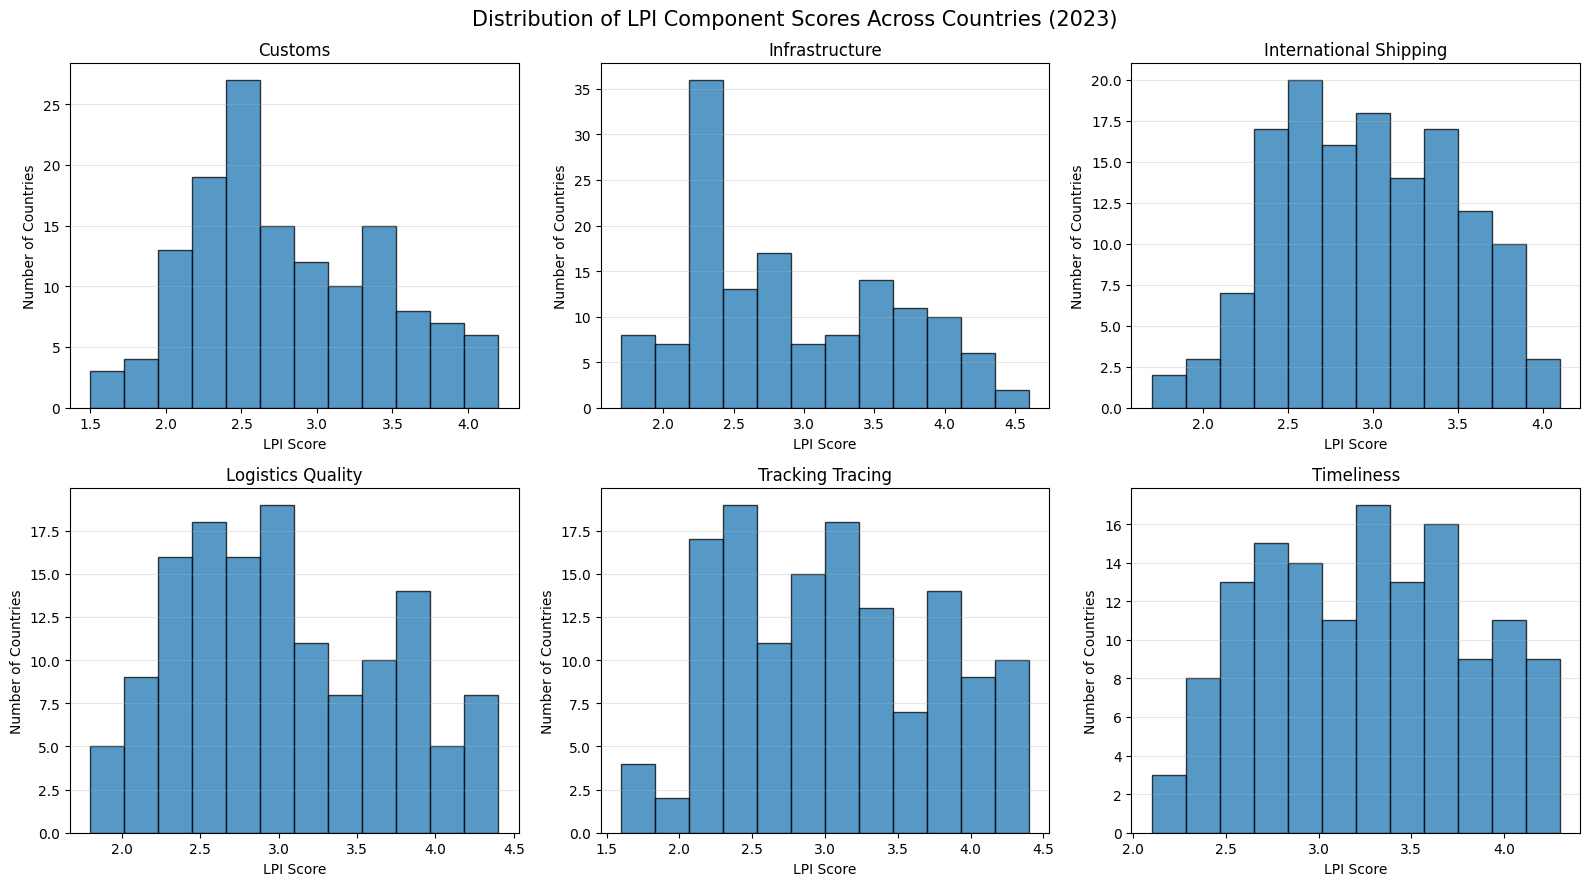

In [84]:
# Créer une figure contenant six histogrammes
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, column in zip(axes.flatten(), feature_columns):
    ax.hist(
        df_clean[column],
        bins=12,
        edgecolor="black",
        alpha=0.75
    )

    ax.set_title(column.replace("_", " "))
    ax.set_xlabel("LPI Score")
    ax.set_ylabel("Number of Countries")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Distribution of LPI Component Scores Across Countries (2023)",
    fontsize=15
)

plt.tight_layout()
plt.show()

### **6.3. Comparaison de la dispersion des composantes**

Nous utilisons des diagrammes en boîte (*boxplots*) afin de comparer la dispersion des scores entre les six composantes du LPI.

Ces graphiques permettent d'identifier la médiane, les quartiles, l'étendue des valeurs et les éventuelles observations atypiques.

Cette comparaison nous aide à comprendre si certaines dimensions de la performance logistique présentent des écarts plus importants entre les pays que d'autres.

Figure saved: figure_02.png


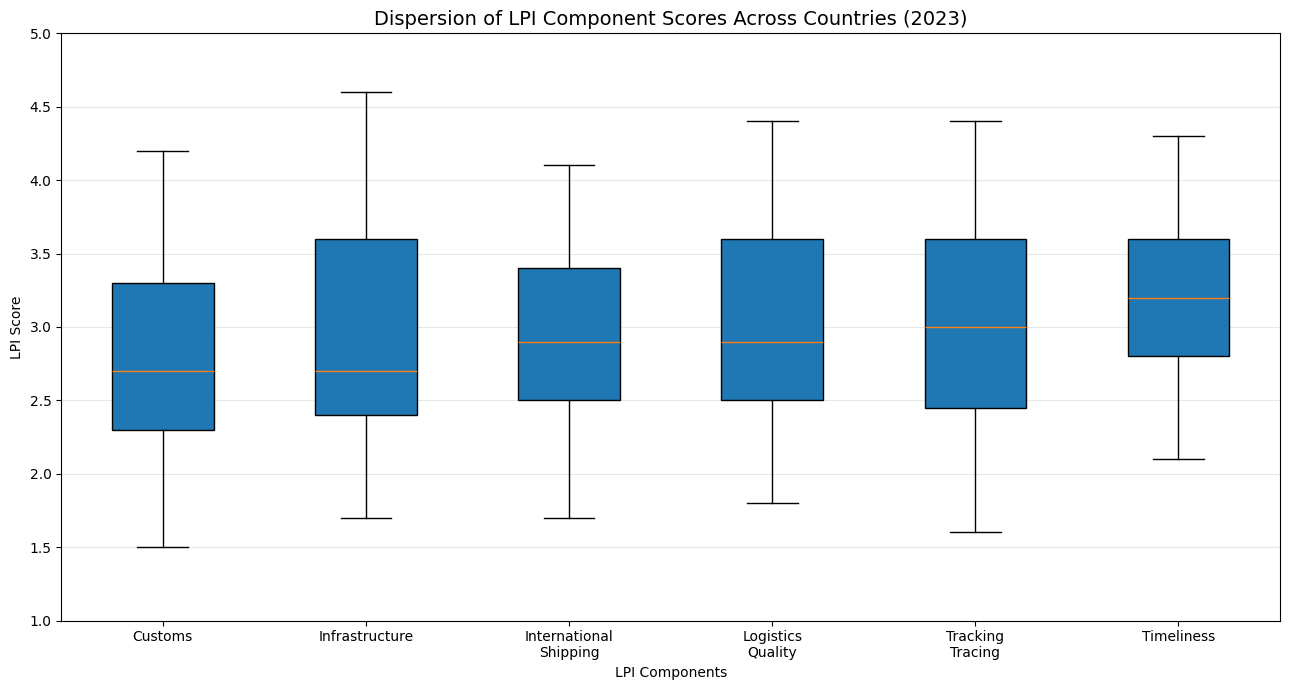

In [85]:
# Préparer les données pour le boxplot
boxplot_data = [
    df_clean[column].dropna()
    for column in feature_columns
]

# Créer le graphique
plt.figure(figsize=(13, 7))

plt.boxplot(
    boxplot_data,
    tick_labels=[col.replace("_", "\n") for col in feature_columns],
    patch_artist=True
)

plt.title(
    "Dispersion of LPI Component Scores Across Countries (2023)",
    fontsize=14
)

plt.xlabel("LPI Components")
plt.ylabel("LPI Score")
plt.ylim(1, 5)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### **6.4. Analyse des corrélations entre les composantes**

Nous analysons les relations entre les six composantes du LPI à travers une matrice de corrélation.

La corrélation permet de mesurer l'intensité et le sens de la relation linéaire entre deux variables.


Cette analyse permet de déterminer si les différentes dimensions de la performance logistique évoluent généralement dans le même sens.

,Customs,Infrastructure,International_Shipping,Logistics_Quality,Tracking_Tracing,Timeliness
Customs,1.000,0.949,0.832,0.929,0.898,0.863
Infrastructure,0.949,1.000,0.845,0.940,0.911,0.863
International_Shipping,0.832,0.845,1.000,0.856,0.870,0.831
Logistics_Quality,0.929,0.940,0.856,1.000,0.934,0.898
Tracking_Tracing,0.898,0.911,0.870,0.934,1.000,0.911
Timeliness,0.863,0.863,0.831,0.898,0.911,1.000


Figure saved: figure_03.png


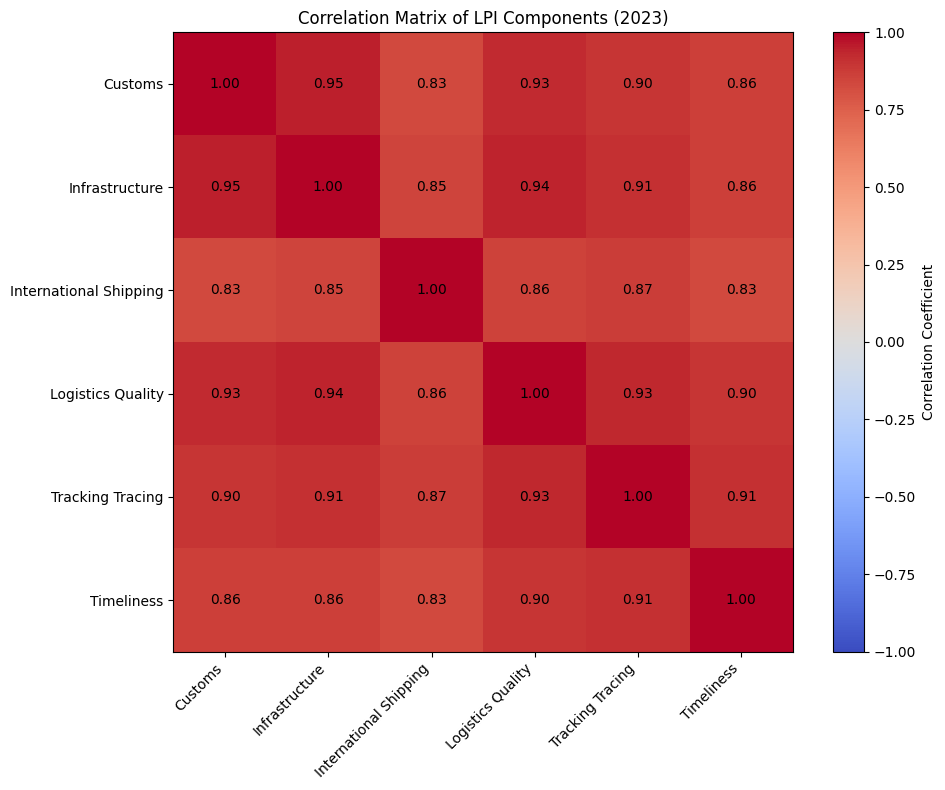

In [86]:
# Calculer la matrice de corrélation
correlation_matrix = df_clean[feature_columns].corr()

# Afficher la matrice
display(correlation_matrix.round(3))

# Visualiser la matrice de corrélation
plt.figure(figsize=(10, 8))

image = plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(image, label="Correlation Coefficient")

plt.xticks(
    range(len(feature_columns)),
    [col.replace("_", " ") for col in feature_columns],
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(feature_columns)),
    [col.replace("_", " ") for col in feature_columns]
)

# Afficher les coefficients dans les cases
for i in range(len(feature_columns)):
    for j in range(len(feature_columns)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

plt.title("Correlation Matrix of LPI Components (2023)")
plt.tight_layout()
plt.show()

### **6.5. Comparaison des performances moyennes**

Nous comparons les scores moyens obtenus par les pays pour chacune des six composantes du LPI.

Cette comparaison permet d'identifier les dimensions dans lesquelles les pays présentent globalement les meilleures performances et celles qui semblent constituer des domaines d'amélioration.

,Average Score
Timeliness,3.242
Tracking_Tracing,3.051
Logistics_Quality,3.029
International_Shipping,2.925
Infrastructure,2.922
Customs,2.800


Figure saved: figure_04.png


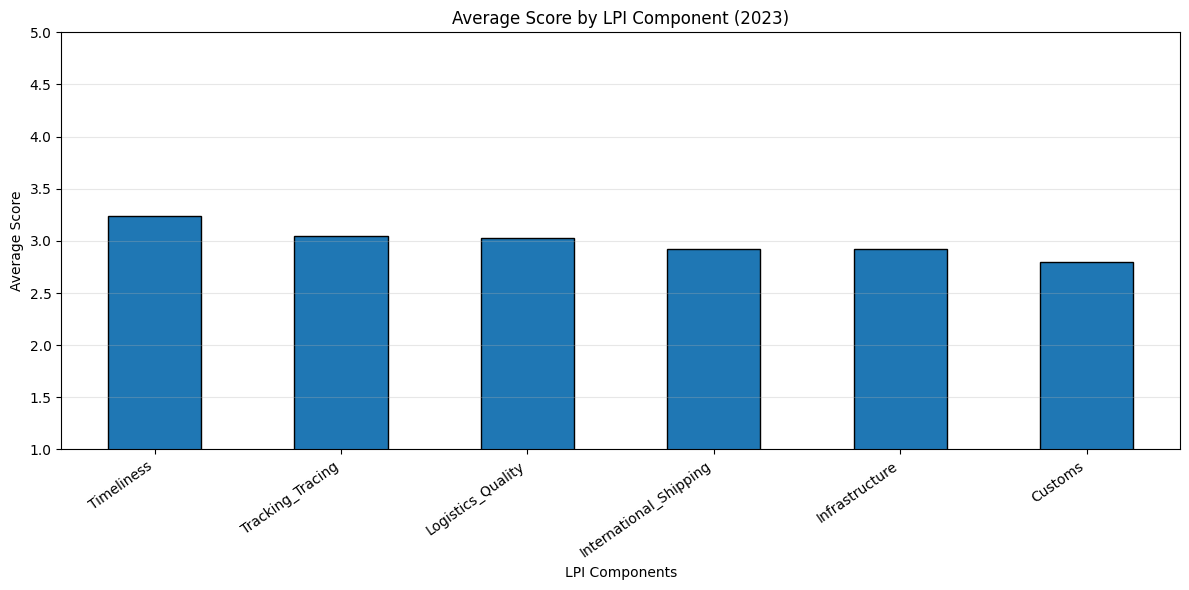

In [87]:
# Calculer le score moyen de chaque composante
component_means = df_clean[feature_columns].mean().sort_values(
    ascending=False
)

display(component_means.to_frame(name="Average Score").round(3))

# Créer un graphique en barres
plt.figure(figsize=(12, 6))

component_means.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Score by LPI Component (2023)")
plt.xlabel("LPI Components")
plt.ylabel("Average Score")
plt.ylim(1, 5)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### **6.6. Comparaison des pays selon leur performance logistique moyenne**

Afin d'obtenir une première comparaison globale des pays, nous calculons pour chacun d'eux la moyenne de ses six scores de composantes.

Cet indicateur synthétique permet de visualiser les différences générales de performance logistique entre les pays et d'identifier ceux qui présentent les moyennes les plus élevées et les plus faibles.

Il sera utilisé uniquement à des fins descriptives et ne remplacera pas les six variables individuelles dans l'analyse de clustering.

In [88]:
# Calculer la moyenne des six composantes pour chaque pays
df_clean["Average_Component_Score"] = df_clean[
    feature_columns
].mean(axis=1)

# Identifier les 10 pays ayant les moyennes les plus élevées
top_10 = df_clean.nlargest(10, "Average_Component_Score")

# Identifier les 10 pays ayant les moyennes les plus faibles
bottom_10 = df_clean.nsmallest(10, "Average_Component_Score")

print("Top 10 countries:")
display(
    top_10[["Country", "Average_Component_Score"]].round(3)
)

print("Bottom 10 countries:")
display(
    bottom_10[["Country", "Average_Component_Score"]].round(3)
)

Top 10 countries:


,Country,Average_Component_Score
111,Singapore,4.317
43,Finland,4.167
121,Switzerland,4.133
48,Germany,4.067
24,Canada,4.050
36,Denmark,4.050
13,Belgium,4.033
91,Netherlands,4.033
58,"Hong Kong SAR, China",4.017
120,Sweden,4.017


Bottom 10 countries:


,Country,Average_Component_Score
0,Afghanistan,1.917
77,Libya,1.917
115,Somalia,1.950
23,Cameroon,2.067
56,Haiti,2.133
3,Angola,2.150
137,"Yemen, Rep.",2.167
80,Madagascar,2.217
33,Cuba,2.250
42,Fiji,2.267


Figure saved: figure_05.png


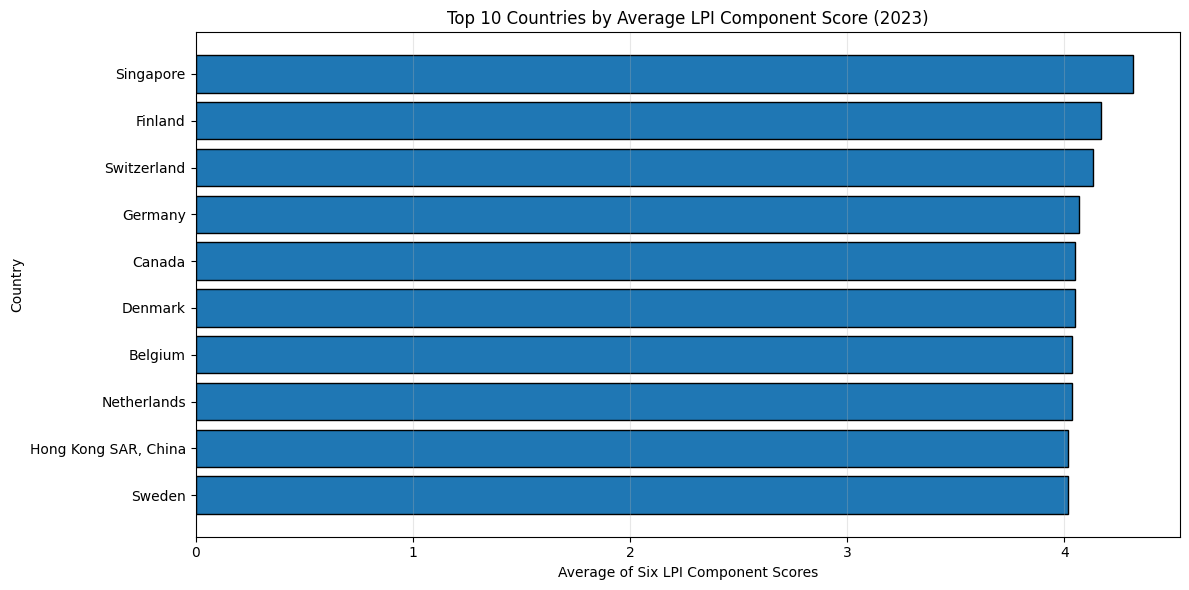

Figure saved: figure_06.png


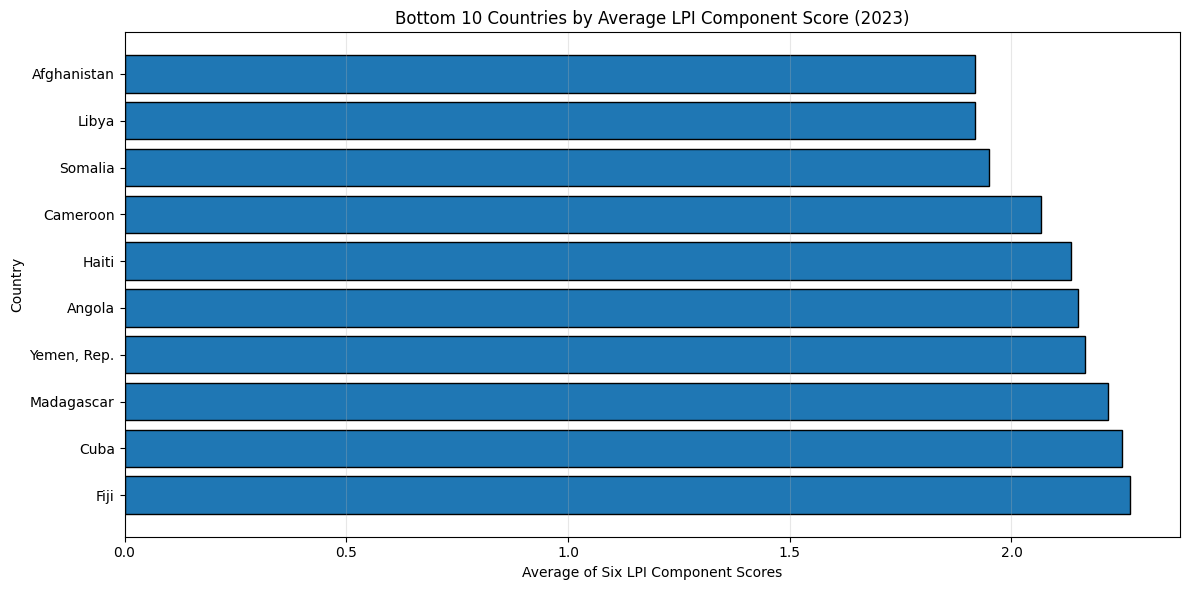

In [89]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10["Country"],
    top_10["Average_Component_Score"],
    edgecolor="black"
)

plt.title("Top 10 Countries by Average LPI Component Score (2023)")
plt.xlabel("Average of Six LPI Component Scores")
plt.ylabel("Country")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))

plt.barh(
    bottom_10["Country"],
    bottom_10["Average_Component_Score"],
    edgecolor="black"
)

plt.title("Bottom 10 Countries by Average LPI Component Score (2023)")
plt.xlabel("Average of Six LPI Component Scores")
plt.ylabel("Country")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### **6.7. Synthèse de l'analyse exploratoire**

L'analyse exploratoire des 139 pays étudiés pour l'année 2023 met en évidence plusieurs différences dans les dimensions de leur performance logistique.

Tout d'abord, les statistiques descriptives montrent que la composante **Timeliness** présente le score moyen le plus élevé, avec une moyenne de 3,242. Elle est suivie par **Tracking and Tracing** (3,051) et **Logistics Quality** (3,029). À l'inverse, **Customs** affiche le score moyen le plus faible, avec 2,800. Ces résultats suggèrent que, dans l'ensemble des pays étudiés, la ponctualité constitue une dimension relativement mieux évaluée, tandis que les procédures douanières représentent un domaine où les performances sont plus faibles.

Les histogrammes et les boxplots montrent également une certaine hétérogénéité entre les pays. Les scores varient selon les composantes, avec des écarts particulièrement visibles pour l'infrastructure, la qualité des services logistiques et le suivi des expéditions. La composante Timeliness présente une médiane de 3,2, supérieure à celle des autres dimensions, tandis que Customs et Infrastructure affichent chacune une médiane de 2,7.

L'analyse des corrélations révèle des relations positives et relativement fortes entre toutes les composantes. Les coefficients de corrélation varient de 0,831 à 0,949. La relation la plus forte est observée entre Customs et Infrastructure (0,949), suivie de celle entre Infrastructure et Logistics Quality (0,940). La corrélation la plus faible concerne International Shipping et Timeliness (0,831). Cela indique que les différentes dimensions de la performance logistique ont tendance à évoluer dans le même sens : les pays qui obtiennent de bons résultats dans une dimension présentent généralement de bonnes performances dans les autres.

Enfin, la comparaison des moyennes des six composantes met en évidence des différences importantes entre les pays. Singapour présente le score moyen synthétique le plus élevé (4,317), suivi de la Finlande (4,167) et de la Suisse (4,133). À l'autre extrémité, l'Afghanistan et la Libye affichent les moyennes les plus faibles (1,917), suivis de la Somalie (1,950).

En conclusion, cette analyse exploratoire montre que les pays présentent des profils logistiques différents, malgré les fortes corrélations observées entre les six composantes. Ces différences justifient le recours aux méthodes de clustering afin de regrouper les pays selon leurs caractéristiques logistiques et d'identifier des profils de performance similaires.

## **7. Construction et préparation des variables**

Après l'analyse exploratoire, nous procédons à la préparation des variables qui seront utilisées dans les algorithmes de clustering.

Notre objectif est de regrouper les pays selon leurs caractéristiques logistiques. Pour cela, nous retenons les six composantes du Logistics Performance Index : Customs, Infrastructure, International Shipping, Logistics Quality, Tracking and Tracing et Timeliness.

Ces six variables constituent les caractéristiques (*features*) de notre analyse.

Les variables d'identification, telles que le nom et le code du pays, sont conservées séparément afin de faciliter l'interprétation des groupes obtenus.

Le score moyen synthétique calculé précédemment est également exclu des variables de clustering, car il s'agit d'un indicateur descriptif construit à partir des six composantes.

In [90]:
# Définir les six variables utilisées pour le clustering
feature_columns = [
    "Customs",
    "Infrastructure",
    "International_Shipping",
    "Logistics_Quality",
    "Tracking_Tracing",
    "Timeliness"
]

# Créer le dataset des variables explicatives
X = df_clean[feature_columns].copy()

# Conserver les informations d'identification des pays
country_info = df_clean[["Country_Code", "Country"]].copy()

# Afficher les premières observations
display(X.head())

# Vérifier les dimensions
print("Dimensions des variables explicatives :", X.shape)
print("Dimensions des informations pays :", country_info.shape)

,Customs,Infrastructure,International_Shipping,Logistics_Quality,Tracking_Tracing,Timeliness
0,2.100,1.700,1.800,2.000,1.600,2.300
1,2.400,2.700,2.800,2.300,2.300,2.500
2,2.300,2.100,3.000,2.200,2.500,2.600
3,1.700,2.100,2.400,2.300,2.300,2.100
4,2.200,2.700,2.900,2.900,3.200,3.400


Dimensions des variables explicatives : (139, 6)
Dimensions des informations pays : (139, 2)


### **7.1. Vérification des variables sélectionnées**

Après la sélection des variables, nous vérifions leur structure, leurs types de données et leur qualité.

Cette vérification permet de nous assurer que les six variables sont bien numériques et qu'elles ne contiennent aucune valeur manquante.

Ces contrôles sont nécessaires avant de procéder à la standardisation des données et à l'application des algorithmes de clustering.

In [91]:
# Vérifier les types de données
print("Types des variables :")
display(X.dtypes)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
display(X.isnull().sum())

# Vérifier les dimensions et les statistiques descriptives
print("\nDimensions :", X.shape)

display(X.describe().round(3))

# Vérifier que toutes les variables sont numériques
print(
    "\nToutes les variables sont numériques :",
    all(pd.api.types.is_numeric_dtype(X[col]) for col in X.columns)
)

# Vérification finale
assert X.shape == (139, 6), "Dimensions inattendues."
assert X.isnull().sum().sum() == 0, "Des valeurs manquantes sont présentes."
assert all(pd.api.types.is_numeric_dtype(X[col]) for col in X.columns), \
    "Certaines variables ne sont pas numériques."

print("\nLes variables sont prêtes pour la prochaine étape.")

Types des variables :


,0
Customs,float64
Infrastructure,float64
International_Shipping,float64
Logistics_Quality,float64
Tracking_Tracing,float64
Timeliness,float64



Valeurs manquantes :


,0
Customs,0
Infrastructure,0
International_Shipping,0
Logistics_Quality,0
Tracking_Tracing,0
Timeliness,0



Dimensions : (139, 6)


,Customs,Infrastructure,International_Shipping,Logistics_Quality,Tracking_Tracing,Timeliness
count,139.000,139.000,139.000,139.000,139.000,139.000
mean,2.800,2.922,2.925,3.029,3.051,3.242
std,0.625,0.721,0.524,0.646,0.675,0.565
min,1.500,1.700,1.700,1.800,1.600,2.100
25%,2.300,2.400,2.500,2.500,2.450,2.800
50%,2.700,2.700,2.900,2.900,3.000,3.200
75%,3.300,3.600,3.400,3.600,3.600,3.600
max,4.200,4.600,4.100,4.400,4.400,4.300



Toutes les variables sont numériques : True

Les variables sont prêtes pour la prochaine étape.


### **7.2. Préparation du jeu de données pour la modélisation**

À ce stade, nous disposons d'une matrice de données contenant 139 pays et six variables numériques.

Cette matrice constitue notre ensemble de données d'entrée pour les futurs algorithmes de clustering.

Les informations relatives aux pays sont conservées séparément afin de pouvoir associer chaque pays au groupe auquel il sera affecté.

Nous sommes maintenant prêts à passer au prétraitement des données, notamment à leur standardisation, avant d'appliquer les méthodes de clustering.

In [92]:
# Afficher la structure finale des données
print("Matrice des variables de clustering :")
display(X.head())

print("\nInformations des pays :")
display(country_info.head())

# Vérifier que les deux ensembles contiennent les mêmes observations
assert len(X) == len(country_info)

print("\nPréparation des données terminée avec succès.")

Matrice des variables de clustering :


,Customs,Infrastructure,International_Shipping,Logistics_Quality,Tracking_Tracing,Timeliness
0,2.100,1.700,1.800,2.000,1.600,2.300
1,2.400,2.700,2.800,2.300,2.300,2.500
2,2.300,2.100,3.000,2.200,2.500,2.600
3,1.700,2.100,2.400,2.300,2.300,2.100
4,2.200,2.700,2.900,2.900,3.200,3.400



Informations des pays :


,Country_Code,Country
0,AFG,Afghanistan
1,ALB,Albania
2,DZA,Algeria
3,AGO,Angola
4,ATG,Antigua and Barbuda



Préparation des données terminée avec succès.


## **8. Prétraitement et standardisation des données**

Avant d'appliquer les algorithmes de clustering, nous procédons à la standardisation des six variables numériques.

Même si les six composantes du LPI sont exprimées sur la même échelle, la standardisation permet de centrer chaque variable autour de zéro et de lui donner un écart-type égal à un.

Cette opération est particulièrement importante pour KMeans et les méthodes de clustering basées sur les distances, car elle permet de rendre les contributions des différentes variables comparables.

Nous utilisons la méthode `StandardScaler` de Scikit-learn pour effectuer cette transformation.

In [93]:
# Initialiser le standardiseur
scaler = StandardScaler()

# Standardiser les six variables
X_scaled = scaler.fit_transform(X)

# Transformer le résultat en DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_columns,
    index=X.index
)

# Afficher les premières observations standardisées
display(X_scaled_df.head())

,Customs,Infrastructure,International_Shipping,Logistics_Quality,Tracking_Tracing,Timeliness
0,-1.124,-1.701,-2.157,-1.599,-2.156,-1.674
1,-0.642,-0.309,-0.240,-1.133,-1.116,-1.319
2,-0.803,-1.144,0.143,-1.288,-0.819,-1.141
3,-1.766,-1.144,-1.007,-1.133,-1.116,-2.029
4,-0.964,-0.309,-0.048,-0.200,0.221,0.280


## **8.1. Vérification de la standardisation**

Après la transformation, nous vérifions que les variables standardisées présentent une moyenne proche de zéro et un écart-type proche de un.

Cette vérification permet de confirmer que la standardisation a été correctement appliquée aux six composantes du LPI.

In [94]:
# Calculer les moyennes et les écarts-types après standardisation
scaled_means = X_scaled_df.mean()
scaled_stds = X_scaled_df.std(ddof=0)

# Afficher les résultats
print("Moyennes après standardisation :")
display(scaled_means.round(4))

print("\nÉcarts-types après standardisation :")
display(scaled_stds.round(4))

Moyennes après standardisation :


,0
Customs,0.000
Infrastructure,-0.000
International_Shipping,-0.000
Logistics_Quality,0.000
Tracking_Tracing,-0.000
Timeliness,-0.000



Écarts-types après standardisation :


,0
Customs,1.000
Infrastructure,1.000
International_Shipping,1.000
Logistics_Quality,1.000
Tracking_Tracing,1.000
Timeliness,1.000


### **8.2. Comparaison avant et après standardisation**

Nous comparons les statistiques des variables avant et après standardisation afin d'observer l'effet de cette transformation.

Les scores originaux conservent leur échelle de 1 à 5, tandis que les scores standardisés sont exprimés dans une échelle commune centrée autour de zéro.

Les données standardisées seront utilisées pour les étapes de modélisation.

In [95]:
# Comparer les statistiques avant et après standardisation
comparison = pd.DataFrame({
    "Original Mean": X.mean(),
    "Original Std": X.std(ddof=0),
    "Scaled Mean": X_scaled_df.mean(),
    "Scaled Std": X_scaled_df.std(ddof=0)
})

display(comparison.round(3))

,Original Mean,Original Std,Scaled Mean,Scaled Std
Customs,2.800,0.623,0.000,1.000
Infrastructure,2.922,0.718,-0.000,1.000
International_Shipping,2.925,0.522,-0.000,1.000
Logistics_Quality,3.029,0.643,0.000,1.000
Tracking_Tracing,3.051,0.673,-0.000,1.000
Timeliness,3.242,0.563,-0.000,1.000


## **9. Modèle de référence (Baseline Model)**

### **9.1. Présentation du modèle KMeans**

Pour établir un premier modèle de référence, nous utilisons l'algorithme KMeans, une méthode de clustering non supervisé.

Cet algorithme permet de regrouper les pays en fonction de la similarité de leurs caractéristiques logistiques. Il cherche à former des groupes dans lesquels les pays sont aussi proches que possible de leur centre de cluster.

Dans notre étude, chaque pays est représenté par les six composantes standardisées du Logistics Performance Index (LPI).

Nous commençons par fixer le nombre de clusters à trois (k = 3). Ce choix constitue une première configuration de référence qui sera ensuite comparée à d'autres configurations et à une méthode alternative.

### **9.2. Application du modèle KMeans**

Nous appliquons l'algorithme KMeans à notre matrice de données standardisées.

Le nombre de clusters est fixé provisoirement à trois. Afin de garantir la reproductibilité des résultats, nous fixons `random_state = 42` et utilisons `n_init = 10` pour effectuer plusieurs initialisations du modèle.

Chaque pays sera ainsi affecté à un cluster en fonction de ses caractéristiques logistiques.

In [96]:
kmeans_baseline = KMeans(
    n_clusters=3,
    random_state=SEED,
    n_init=30
)

baseline_labels = kmeans_baseline.fit_predict(X_scaled_df)

baseline_results = country_info.copy()
baseline_results["Cluster"] = baseline_labels

display(baseline_results.head(10))

,Country_Code,Country,Cluster
0,AFG,Afghanistan,0
1,ALB,Albania,0
2,DZA,Algeria,0
3,AGO,Angola,0
4,ATG,Antigua and Barbuda,2
5,ARG,Argentina,2
6,ARM,Armenia,0
7,AUS,Australia,1
8,AUT,Austria,1
9,BHS,"Bahamas, The",0


### **9.3. Évaluation du modèle de référence**

Afin d'évaluer la qualité initiale de notre segmentation, nous utilisons deux indicateurs :

- **Inertia (WCSS)** : mesure la somme des distances au carré entre les observations et les centres de leurs clusters. Une valeur faible indique des groupes relativement compacts.
- **Silhouette Score** : mesure la cohésion des observations au sein de leurs clusters et leur séparation par rapport aux autres groupes. Sa valeur varie entre -1 et +1. Plus elle est élevée, meilleure est généralement la séparation des clusters.

Ces deux indicateurs permettent d'obtenir une première évaluation de notre modèle KMeans.

In [97]:
# Calculer l'inertie du modèle
baseline_inertia = kmeans_baseline.inertia_

# Calculer le score de Silhouette
baseline_silhouette = silhouette_score(
    X_scaled_df,
    baseline_labels
)

# Afficher les résultats
print("Évaluation du modèle KMeans de référence")
print("----------------------------------------")
print("Nombre de clusters :", 3)
print("Inertia :", round(baseline_inertia, 3))
print("Silhouette Score :", round(baseline_silhouette, 3))

Évaluation du modèle KMeans de référence
----------------------------------------
Nombre de clusters : 3
Inertia : 164.742
Silhouette Score : 0.432


### **9.4. Répartition des pays par cluster**

Après l'application de KMeans, nous examinons la répartition des pays entre les trois clusters.

Cette analyse permet de connaître le nombre et le pourcentage de pays appartenant à chaque groupe.

Elle nous aide également à vérifier si la segmentation produit des groupes relativement équilibrés ou si certains clusters regroupent une proportion beaucoup plus importante de pays.

In [98]:
# Calculer le nombre de pays dans chaque cluster
cluster_distribution = (
    baseline_results["Cluster"]
    .value_counts()
    .sort_index()
)

print("Nombre de pays par cluster :")
display(
    cluster_distribution.to_frame(
        name="Number of Countries"
    )
)

# Calculer le pourcentage de pays dans chaque cluster
cluster_percentages = (
    baseline_results["Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Pourcentage de pays par cluster :")
display(
    cluster_percentages.round(2).to_frame(
        name="Percentage"
    )
)

Nombre de pays par cluster :


,Number of Countries
Cluster,
0,61
1,37
2,41


Pourcentage de pays par cluster :


,Percentage
Cluster,
0,43.880
1,26.620
2,29.500


### **9.5. Analyse des profils logistiques des clusters**

Afin de mieux comprendre les groupes obtenus, nous calculons les scores moyens des six composantes du LPI pour chaque cluster.

Cette analyse permet de comparer les performances logistiques des différents groupes et d'identifier leurs principales caractéristiques.

Nous utilisons ici les scores originaux du LPI, et non les données standardisées, afin de faciliter l'interprétation des résultats sur l'échelle initiale de 1 à 5.

In [99]:
# Créer une copie des données originales
X_baseline = X.copy()

# Ajouter les labels des clusters
X_baseline["Cluster"] = baseline_labels

# Calculer les moyennes des six composantes par cluster
cluster_profiles = (
    X_baseline
    .groupby("Cluster")[feature_columns]
    .mean()
)

# Afficher les profils moyens
print("Profils logistiques moyens des clusters :")
display(cluster_profiles.round(3))

Profils logistiques moyens des clusters :


,Customs,Infrastructure,International_Shipping,Logistics_Quality,Tracking_Tracing,Timeliness
Cluster,,,,,,
0,2.264,2.284,2.464,2.446,2.428,2.746
1,3.627,3.892,3.535,3.889,3.935,3.946
2,2.851,2.995,3.061,3.120,3.180,3.346


## **9.6. Visualisation des pays selon les scores de douanes et d'infrastructures**

Le nuage de points représente chaque pays selon ses scores en matière de douanes et d'infrastructures. La couleur de chaque point indique le cluster attribué par KMeans.

Cette représentation permet d'observer la répartition des pays selon ces deux dimensions. Toutefois, elle ne reflète pas l'ensemble des six variables utilisées pour construire les clusters. Une représentation complémentaire à l'aide de l'ACP sera donc utilisée dans la section suivante.

Figure saved: figure_07.png


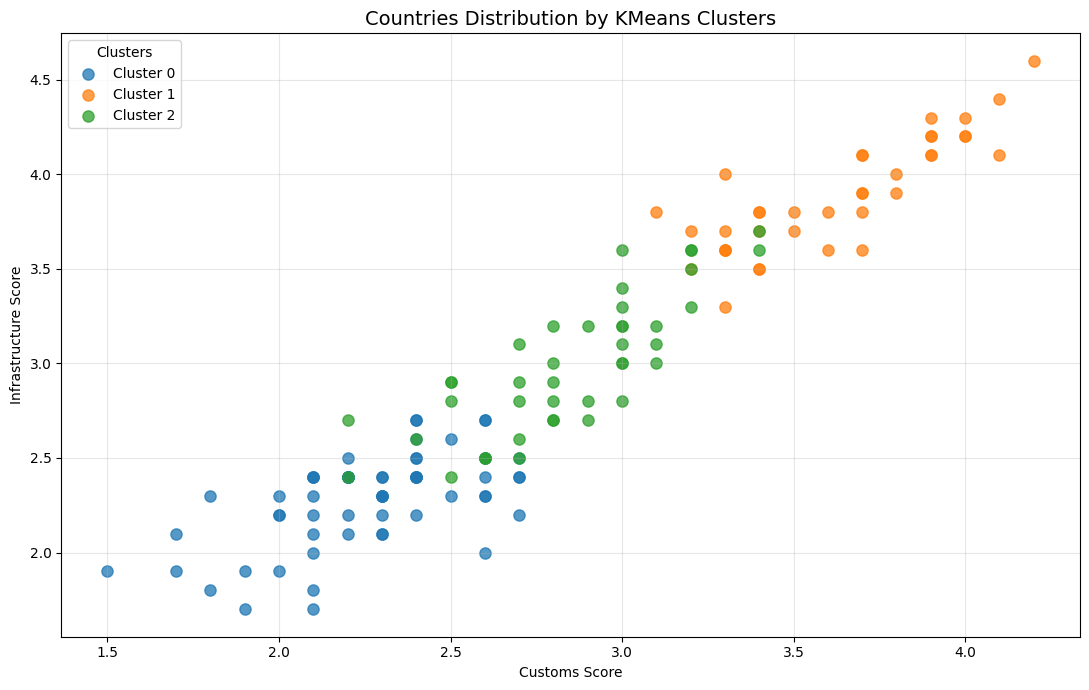

In [100]:
# Créer un DataFrame contenant les scores et les clusters
df_scatter = X.copy()
df_scatter["Cluster"] = baseline_labels

# Créer le nuage de points
plt.figure(figsize=(11, 7))

for cluster in sorted(df_scatter["Cluster"].unique()):

    cluster_data = df_scatter[
        df_scatter["Cluster"] == cluster
    ]

    plt.scatter(
        cluster_data["Customs"],
        cluster_data["Infrastructure"],
        label=f"Cluster {cluster}",
        s=65,
        alpha=0.75
    )

# Personnalisation du graphique
plt.title("Countries Distribution by KMeans Clusters", fontsize=14)
plt.xlabel("Customs Score")
plt.ylabel("Infrastructure Score")

plt.legend(title="Clusters")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### **9.7. Conclusion du modèle de référence**

L'application de l'algorithme KMeans avec trois clusters nous a permis d'obtenir une première segmentation des pays selon leurs six composantes de performance logistique.

L'évaluation initiale du modèle repose sur l'inertie et le score de Silhouette. La répartition des pays et l'analyse des profils moyens permettent également de mieux comprendre les caractéristiques des groupes obtenus.

Cette première segmentation constitue une référence pour la suite de notre étude. Toutefois, le nombre de clusters étant fixé provisoirement à trois, il est nécessaire d'examiner d'autres configurations afin d'identifier une segmentation plus pertinente.

Dans les prochaines étapes, nous comparerons plusieurs valeurs de K et une méthode alternative de clustering afin d'évaluer la qualité et la stabilité des groupes obtenus.

# **10. Analyse en composantes principales (ACP)**

## **10.1. Présentation de l'analyse en composantes principales (ACP)**

L'analyse en composantes principales (ACP) est une méthode de réduction de dimensionnalité qui permet de transformer plusieurs variables corrélées en un ensemble de nouvelles variables appelées composantes principales.

Dans notre étude, l'ACP est appliquée aux six composantes standardisées du Logistics Performance Index (LPI).

Cette méthode poursuit trois objectifs :
- mesurer la part de l'information expliquée par chaque composante principale ;
- identifier les variables qui contribuent le plus à la construction des axes ;
- représenter les pays dans un espace à deux dimensions afin de faciliter la visualisation des groupes.

L'ACP sera utilisée principalement pour l'analyse et la visualisation. Les modèles de clustering principaux continueront à être entraînés sur les six variables standardisées.

## **10.2. Application de l’ACP**

In [101]:
# Importer la classe PCA
from sklearn.decomposition import PCA

# Appliquer l'ACP aux six variables standardisées
pca = PCA()

# Calculer les coordonnées des pays dans le nouvel espace
pca_coordinates = pca.fit_transform(X_scaled_df)

# Créer un DataFrame contenant les composantes principales
pca_df = pd.DataFrame(
    pca_coordinates,
    columns=[f"PC{i+1}" for i in range(X_scaled_df.shape[1])],
    index=X_scaled_df.index
)

# Calculer la variance expliquée et la variance cumulée
pca_variance = pd.DataFrame({
    "Explained Variance (%)": pca.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)": (
        pca.explained_variance_ratio_.cumsum() * 100
    )
}, index=[f"PC{i+1}" for i in range(X_scaled_df.shape[1])])

print("Variance expliquée par les composantes principales :")
display(pca_variance.round(2))

# Afficher les premières coordonnées des pays
display(pca_df.head())

Variance expliquée par les composantes principales :


,Explained Variance (%),Cumulative Variance (%)
PC1,90.780,90.780
PC2,3.410,94.190
PC3,2.750,96.930
PC4,1.330,98.270
PC5,0.940,99.210
PC6,0.790,100.000


,PC1,PC2,PC3,PC4,PC5,PC6
0,-4.243,-0.725,-0.052,-0.430,0.097,-0.306
1,-1.950,0.154,-0.905,-0.228,-0.138,0.342
2,-2.081,0.896,-0.560,-0.099,-0.343,-0.178
3,-3.343,0.203,-0.547,0.698,0.195,0.217
4,-0.421,0.555,0.658,0.376,0.080,0.356


## **10.3. Contribution des variables aux axes**

In [102]:
# Calculer les coordonnées des variables sur les axes
pca_loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=feature_columns,
    columns=[f"PC{i+1}" for i in range(len(feature_columns))]
)

# Calculer les contributions des variables aux composantes
pca_contributions = (
    pca.components_.T ** 2
) * 100

pca_contributions = pd.DataFrame(
    pca_contributions,
    index=feature_columns,
    columns=[f"PC{i+1}" for i in range(len(feature_columns))]
)

print("Coordonnées des variables sur les axes :")
display(pca_loadings.iloc[:, :2].round(3))

print("\nContribution des variables aux deux premiers axes (%) :")
display(pca_contributions.iloc[:, :2].round(2))

Coordonnées des variables sur les axes :


,PC1,PC2
Customs,0.961,-0.187
Infrastructure,0.968,-0.160
International_Shipping,0.918,0.366
Logistics_Quality,0.976,-0.087
Tracking_Tracing,0.970,0.029
Timeliness,0.942,0.058



Contribution des variables aux deux premiers axes (%) :


,PC1,PC2
Customs,16.850,16.960
Infrastructure,17.070,12.440
International_Shipping,15.360,64.900
Logistics_Quality,17.380,3.640
Tracking_Tracing,17.170,0.420
Timeliness,16.180,1.650


## **10.4. Visualisation de la variance expliquée**

Figure saved: figure_08.png


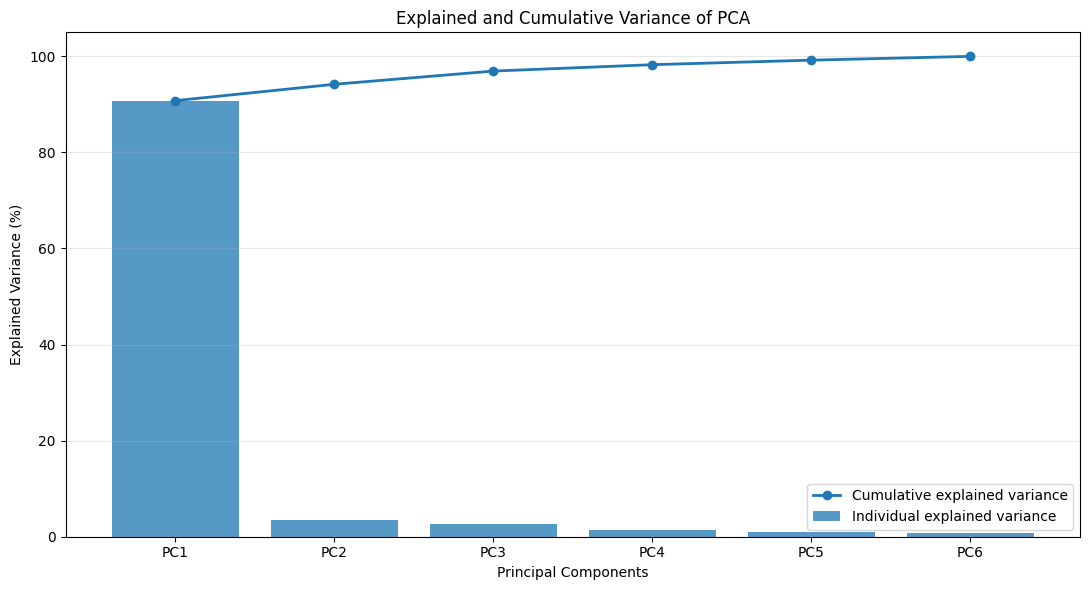

In [103]:
# Préparer les données du graphique
components = np.arange(1, len(pca_variance) + 1)
individual_variance = pca_variance["Explained Variance (%)"]
cumulative_variance = pca_variance["Cumulative Variance (%)"]

# Créer le graphique
plt.figure(figsize=(11, 6))

plt.bar(
    components,
    individual_variance,
    alpha=0.75,
    label="Individual explained variance"
)

plt.plot(
    components,
    cumulative_variance,
    marker="o",
    linewidth=2,
    label="Cumulative explained variance"
)

plt.xticks(components, pca_variance.index)
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Explained and Cumulative Variance of PCA")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## **10.5. Projection des pays sur le plan factoriel**

Figure saved: figure_09.png


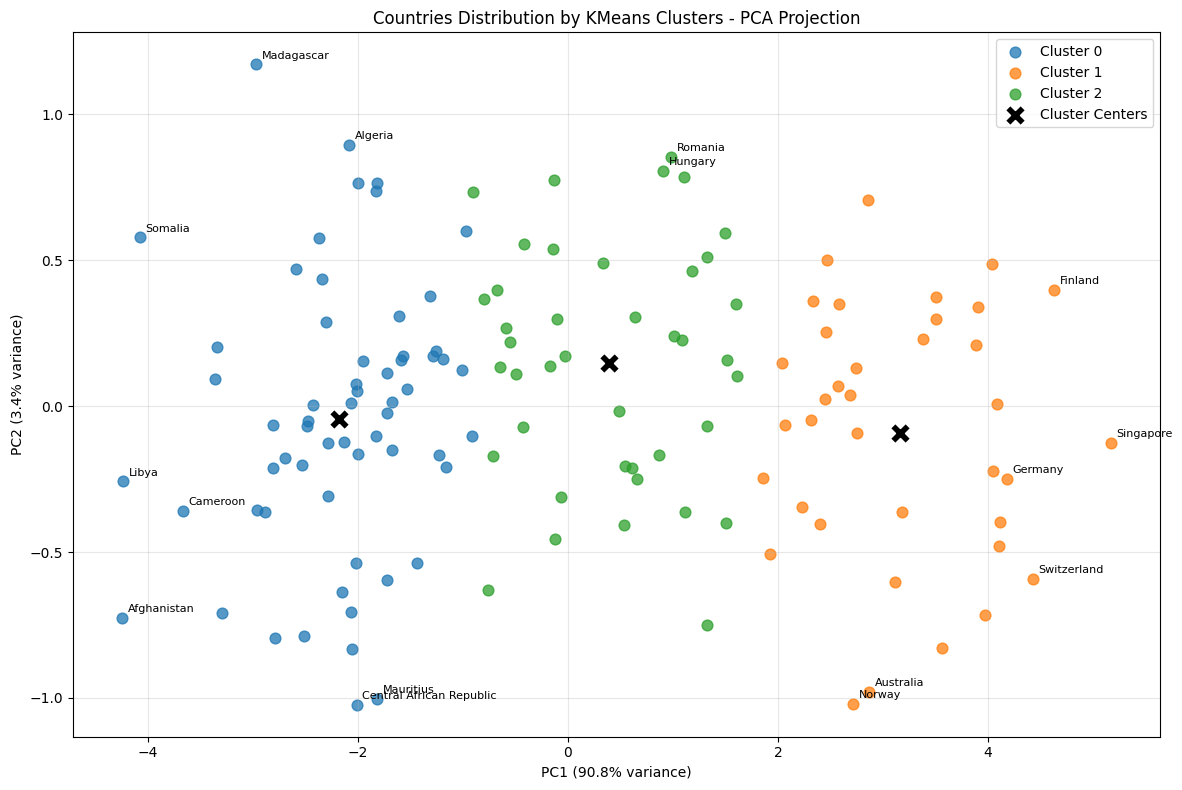

In [104]:
# Créer une figure
plt.figure(figsize=(12, 8))

# Représenter chaque cluster
for cluster in sorted(np.unique(baseline_labels)):
    mask = baseline_labels == cluster

    plt.scatter(
        pca_df.loc[mask, "PC1"],
        pca_df.loc[mask, "PC2"],
        s=60,
        alpha=0.75,
        label=f"Cluster {cluster}"
    )

# Projeter les centres KMeans dans l'espace PCA
centers_pca = pca.transform(
    kmeans_baseline.cluster_centers_
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=220,
    color="black",
    edgecolor="white",
    linewidth=1.2,
    label="Cluster Centers"
)

# Ajouter les noms de quelques pays extrêmes sur les deux axes
extreme_indices = set(
    pca_df["PC1"].nlargest(4).index
).union(
    pca_df["PC1"].nsmallest(4).index
).union(
    pca_df["PC2"].nlargest(4).index
).union(
    pca_df["PC2"].nsmallest(4).index
)

for idx in extreme_indices:
    country = country_info.loc[idx, "Country"]

    plt.annotate(
        country,
        (pca_df.loc[idx, "PC1"], pca_df.loc[idx, "PC2"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel(
    f"PC1 ({pca_variance.iloc[0]['Explained Variance (%)']:.1f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca_variance.iloc[1]['Explained Variance (%)']:.1f}% variance)"
)

plt.title("Countries Distribution by KMeans Clusters - PCA Projection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **10.6. Interprétation des résultats de l'ACP**

L'analyse en composantes principales met en évidence une forte concentration de l'information sur les deux premiers axes factoriels.

La première composante principale (PC1) explique 90,78 % de la variance totale. Ses coefficients sont tous positifs et relativement proches pour les six variables étudiées. Elle représente ainsi une dimension générale de la performance logistique des pays. Les pays présentant des scores élevés dans les différentes composantes du LPI tendent à obtenir des valeurs élevées sur cet axe.

La deuxième composante principale (PC2) explique 3,41 % de la variance totale. Elle est principalement associée à la composante International Shipping, qui présente un coefficient positif de 0,366 et contribue à hauteur de 64,90 % à la construction de cet axe. À l'inverse, Customs et Infrastructure présentent des coefficients négatifs. PC2 traduit ainsi une différence secondaire entre les performances liées aux expéditions internationales et celles relatives aux douanes et aux infrastructures.

Au total, les deux premiers axes expliquent 94,19 % de la variance initiale. Cette proportion élevée montre que le plan factoriel PC1-PC2 constitue une représentation pertinente de la structure générale des données.

L'ACP confirme ainsi l'existence d'une dimension commune importante entre les six composantes de la performance logistique. Elle facilite également la visualisation des pays et des groupes identifiés par les méthodes de clustering.

Il convient toutefois de rappeler que l'ACP est utilisée ici comme méthode de réduction dimensionnelle et de visualisation. Les modèles de clustering sont toujours entraînés sur les six variables standardisées.

# **11. Choix du nombre optimal de clusters**

# **11.1. Détermination du nombre optimal de clusters**

Le choix du nombre de clusters constitue une étape importante dans notre analyse. Un nombre trop faible peut regrouper des pays présentant des caractéristiques différentes, tandis qu'un nombre trop élevé peut produire une segmentation trop fragmentée.

Pour déterminer une configuration pertinente, nous comparons plusieurs valeurs de K, allant de 2 à 8, à travers les méthodes KMeans et Agglomerative Clustering.

Nous utilisons plusieurs critères complémentaires :
- **Silhouette Score** : évalue la cohésion et la séparation des groupes.
- **Davies-Bouldin Index** : mesure la similarité entre les clusters ; une valeur faible est préférable.
- **Calinski-Harabasz Index** : compare la dispersion entre les groupes à la dispersion à l'intérieur des groupes.
- **Inertia** : mesure la dispersion intra-cluster pour KMeans.
- **Stabilité** : vérifie si la segmentation KMeans reste similaire lorsque les pays sont rééchantillonnés.

Le choix final ne reposera donc pas uniquement sur le score de silhouette, mais également sur l'équilibre des groupes et leur interprétation économique.

## **11.2. Comparaison des configurations**

In [105]:
# Importer les métriques nécessaires
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.cluster import KMeans, AgglomerativeClustering

# Définir les valeurs de K à tester
K_RANGE = range(2, 9)

# Définir les méthodes à comparer
clustering_models = {
    "KMeans": lambda k: KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=30
    ),

    "Agglomerative - Ward": lambda k: AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    ),

    "Agglomerative - Complete": lambda k: AgglomerativeClustering(
        n_clusters=k,
        linkage="complete"
    ),

    "Agglomerative - Average": lambda k: AgglomerativeClustering(
        n_clusters=k,
        linkage="average"
    )
}

# Stocker les résultats
comparison_results = []

for model_name, model_function in clustering_models.items():

    for k in K_RANGE:

        model = model_function(k)
        labels = model.fit_predict(X_scaled_df)

        comparison_results.append({
            "Model": model_name,
            "K": k,
            "Silhouette": silhouette_score(
                X_scaled_df, labels
            ),
            "Davies_Bouldin": davies_bouldin_score(
                X_scaled_df, labels
            ),
            "Calinski_Harabasz": calinski_harabasz_score(
                X_scaled_df, labels
            ),
            "Minimum_Cluster_Size": np.bincount(labels).min(),
            "Maximum_Cluster_Size": np.bincount(labels).max(),
            "Inertia": (
                model.inertia_
                if model_name == "KMeans"
                else np.nan
            )
        })

# Créer le tableau comparatif
clustering_comparison = pd.DataFrame(comparison_results)

display(
    clustering_comparison.round(3)
)

,Model,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Minimum_Cluster_Size,Maximum_Cluster_Size,Inertia
0,KMeans,2,0.565,0.604,317.363,60,79,251.469
1,KMeans,3,0.432,0.780,276.246,37,61,164.742
2,KMeans,4,0.339,0.938,246.485,27,49,128.754
3,KMeans,5,0.320,1.005,219.238,16,48,110.545
4,KMeans,6,0.288,1.125,209.529,14,38,93.950
5,KMeans,7,0.281,1.225,188.606,12,27,87.120
6,KMeans,8,0.248,1.262,171.510,6,22,82.049
7,Agglomerative - Ward,2,0.565,0.604,317.363,60,79,NaN
8,Agglomerative - Ward,3,0.409,0.804,237.987,24,79,NaN
9,Agglomerative - Ward,4,0.326,0.974,235.623,24,47,NaN


## **11.3. Évaluation de la stabilité de KMeans par rééchantillonnage bootstrap**

Cette analyse permet d'examiner la robustesse de la segmentation en comparant les groupes obtenus sur les données initiales avec ceux produits après plusieurs rééchantillonnages bootstrap.

In [106]:
# Tester la stabilité de KMeans par bootstrap
from sklearn.metrics import adjusted_rand_score
B = 50

rng = np.random.default_rng(SEED)

stability_results = []

Z = X_scaled_df.to_numpy()

for k in K_RANGE:

    # Partition de référence
    reference_model = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=30
    )

    reference_labels = reference_model.fit_predict(Z)

    ari_scores = []

    for b in range(B):

        # Tirage bootstrap des pays
        bootstrap_indices = rng.integers(
            0, len(Z), size=len(Z)
        )

        bootstrap_sample = Z[bootstrap_indices]

        # Réentraîner KMeans sur l'échantillon bootstrap
        bootstrap_model = KMeans(
            n_clusters=k,
            random_state=SEED + b,
            n_init=20
        )

        bootstrap_model.fit(bootstrap_sample)

        # Réaffecter tous les pays aux nouveaux centres
        predicted_labels = bootstrap_model.predict(Z)

        # Comparer les deux partitions
        ari = adjusted_rand_score(
            reference_labels,
            predicted_labels
        )

        ari_scores.append(ari)

    stability_results.append({
        "K": k,
        "Mean_ARI": np.mean(ari_scores),
        "Std_ARI": np.std(ari_scores),
        "Minimum_ARI": np.min(ari_scores)
    })

kmeans_stability = pd.DataFrame(stability_results)

print("Stabilité de KMeans selon le nombre de clusters :")
display(kmeans_stability.round(3))

Stabilité de KMeans selon le nombre de clusters :


,K,Mean_ARI,Std_ARI,Minimum_ARI
0,2,0.975,0.047,0.807
1,3,0.873,0.115,0.442
2,4,0.779,0.136,0.533
3,5,0.683,0.154,0.442
4,6,0.836,0.093,0.524
5,7,0.737,0.103,0.530
6,8,0.667,0.073,0.484


## **11.4. Visualisation des critères de sélection**

Figure saved: figure_10.png


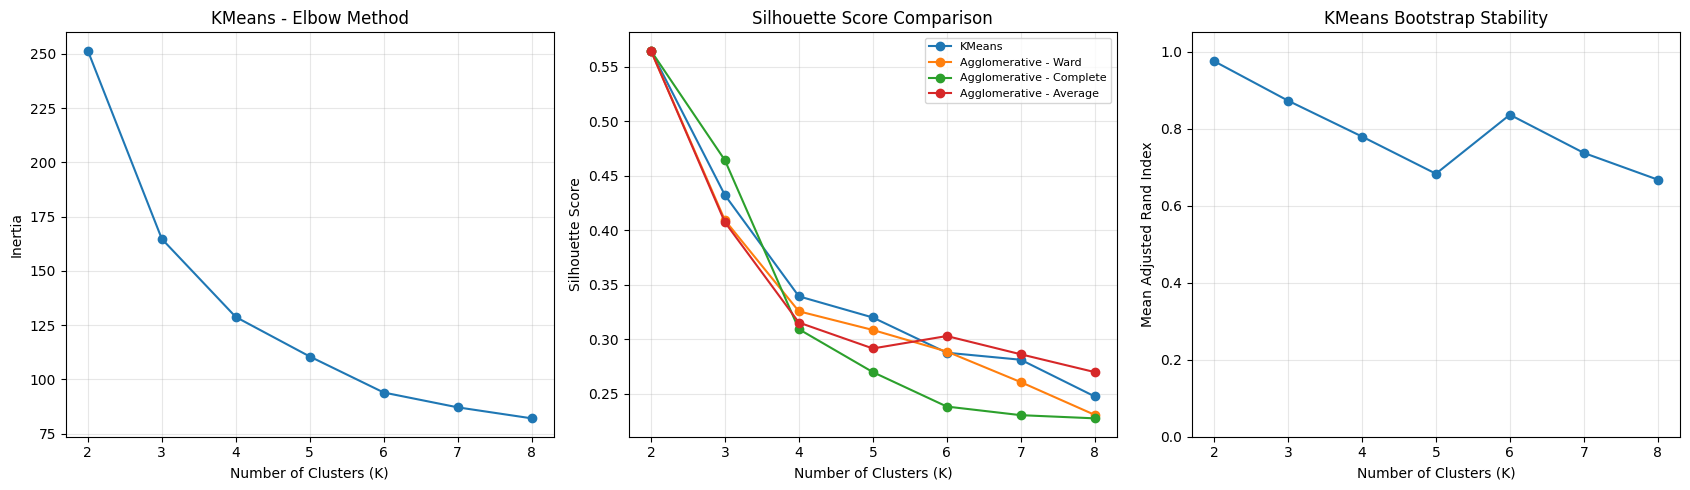

In [107]:
# Préparer les résultats KMeans
kmeans_results = clustering_comparison[
    clustering_comparison["Model"] == "KMeans"
].sort_values("K")

# Créer trois graphiques
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Inertie
axes[0].plot(
    kmeans_results["K"],
    kmeans_results["Inertia"],
    marker="o"
)
axes[0].set_title("KMeans - Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

# 2. Silhouette des différentes méthodes
for model_name in clustering_models:

    subset = clustering_comparison[
        clustering_comparison["Model"] == model_name
    ]

    axes[1].plot(
        subset["K"],
        subset["Silhouette"],
        marker="o",
        label=model_name
    )

axes[1].set_title("Silhouette Score Comparison")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

# 3. Stabilité KMeans
axes[2].plot(
    kmeans_stability["K"],
    kmeans_stability["Mean_ARI"],
    marker="o"
)

axes[2].set_title("KMeans Bootstrap Stability")
axes[2].set_xlabel("Number of Clusters (K)")
axes[2].set_ylabel("Mean Adjusted Rand Index")
axes[2].set_ylim(0, 1.05)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## **11.5. Tableau de synthèse des résultats**

In [108]:
# Fusionner les résultats de stabilité avec les résultats KMeans
kmeans_summary = kmeans_results.merge(
    kmeans_stability,
    on="K"
)

print("Synthèse des performances de KMeans :")
display(kmeans_summary.round(3))

print("\nMeilleures configurations selon la silhouette :")

display(
    clustering_comparison.sort_values(
        "Silhouette",
        ascending=False
    ).groupby("Model").head(3).round(3)
)

Synthèse des performances de KMeans :


,Model,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Minimum_Cluster_Size,Maximum_Cluster_Size,Inertia,Mean_ARI,Std_ARI,Minimum_ARI
0,KMeans,2,0.565,0.604,317.363,60,79,251.469,0.975,0.047,0.807
1,KMeans,3,0.432,0.780,276.246,37,61,164.742,0.873,0.115,0.442
2,KMeans,4,0.339,0.938,246.485,27,49,128.754,0.779,0.136,0.533
3,KMeans,5,0.320,1.005,219.238,16,48,110.545,0.683,0.154,0.442
4,KMeans,6,0.288,1.125,209.529,14,38,93.950,0.836,0.093,0.524
5,KMeans,7,0.281,1.225,188.606,12,27,87.120,0.737,0.103,0.530
6,KMeans,8,0.248,1.262,171.510,6,22,82.049,0.667,0.073,0.484



Meilleures configurations selon la silhouette :


,Model,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Minimum_Cluster_Size,Maximum_Cluster_Size,Inertia
0,KMeans,2,0.565,0.604,317.363,60,79,251.469
7,Agglomerative - Ward,2,0.565,0.604,317.363,60,79,NaN
21,Agglomerative - Average,2,0.565,0.604,317.363,60,79,NaN
14,Agglomerative - Complete,2,0.565,0.604,317.363,60,79,NaN
15,Agglomerative - Complete,3,0.464,0.699,231.652,16,79,NaN
1,KMeans,3,0.432,0.780,276.246,37,61,164.742
8,Agglomerative - Ward,3,0.409,0.804,237.987,24,79,NaN
22,Agglomerative - Average,3,0.407,0.809,188.165,7,72,NaN
2,KMeans,4,0.339,0.938,246.485,27,49,128.754
9,Agglomerative - Ward,4,0.326,0.974,235.623,24,47,NaN


## **Interprétation**

Les résultats montrent clairement que K=2 obtient les meilleures valeurs selon les principaux critères :
- Silhouette la plus élevée : 0,565.
- Davies-Bouldin le plus faible : 0,604.
- Calinski-Harabasz le plus élevé : 317,363.
- Stabilité moyenne ARI la plus élevée : 0,975.
Cela signifie que deux groupes constituent la segmentation la plus nette et la plus stable parmi les configurations KMeans testées.

Lorsque K augmente, la silhouette diminue progressivement. Cela suggère que la division en groupes supplémentaires rend la séparation globale moins nette.

**Attention** : K=2 est le meilleur choix statistique selon les résultats disponibles, mais cela ne signifie pas automatiquement qu'il est le meilleur choix économique. Trois groupes peuvent être plus intéressants si l'objectif est de distinguer les pays à performance faible, intermédiaire et élevée.

# **12. Comparaison finale des modèles**

## **12.1. Comparaison des partitions obtenues avec K=2**

Les résultats précédents montrent que les quatre configurations testées obtiennent les mêmes valeurs de Silhouette pour K=2.

Nous comparons maintenant directement les partitions produites par KMeans et Agglomerative Clustering à l'aide de l'Adjusted Rand Index (ARI). Cet indicateur permet de mesurer le degré de similarité entre deux segmentations, indépendamment des numéros attribués aux clusters.

In [109]:
from sklearn.metrics import adjusted_rand_score

# Entraîner les quatre modèles avec K=2
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=SEED,
    n_init=30
)

labels_kmeans_2 = kmeans_2.fit_predict(X_scaled_df)

agglo_ward_2 = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

labels_ward_2 = agglo_ward_2.fit_predict(X_scaled_df)

agglo_complete_2 = AgglomerativeClustering(
    n_clusters=2,
    linkage="complete"
)

labels_complete_2 = agglo_complete_2.fit_predict(X_scaled_df)

agglo_average_2 = AgglomerativeClustering(
    n_clusters=2,
    linkage="average"
)

labels_average_2 = agglo_average_2.fit_predict(X_scaled_df)

# Comparer les partitions
partition_comparison = pd.DataFrame({
    "Comparison": [
        "KMeans vs Ward",
        "KMeans vs Complete",
        "KMeans vs Average",
        "Ward vs Complete",
        "Ward vs Average",
        "Complete vs Average"
    ],
    "ARI": [
        adjusted_rand_score(labels_kmeans_2, labels_ward_2),
        adjusted_rand_score(labels_kmeans_2, labels_complete_2),
        adjusted_rand_score(labels_kmeans_2, labels_average_2),
        adjusted_rand_score(labels_ward_2, labels_complete_2),
        adjusted_rand_score(labels_ward_2, labels_average_2),
        adjusted_rand_score(labels_complete_2, labels_average_2)
    ]
})

display(partition_comparison.round(3))

,Comparison,ARI
0,KMeans vs Ward,1.000
1,KMeans vs Complete,1.000
2,KMeans vs Average,1.000
3,Ward vs Complete,1.000
4,Ward vs Average,1.000
5,Complete vs Average,1.000


# **13. Sélection et entraînement du modèle final**

### **13.1. Sélection du modèle final**

La comparaison des différentes configurations de KMeans montre que la segmentation en deux clusters présente les meilleures performances statistiques parmi les valeurs de K testées. Elle obtient notamment un score de Silhouette de 0,565, un indice de Davies-Bouldin de 0,604 et un indice de Calinski-Harabasz de 317,363.

Cependant, le choix du nombre de clusters ne repose pas uniquement sur les critères statistiques. Il doit également tenir compte de l'objectif de l'étude et de la pertinence économique des groupes obtenus.

Dans le cadre de notre projet, qui vise à analyser les disparités de performance logistique entre les pays à l'échelle internationale, une segmentation en trois clusters présente un intérêt particulier. Elle permet de distinguer trois catégories de pays : ceux ayant un niveau de performance logistique élevé, ceux présentant un niveau intermédiaire et ceux dont les performances sont relativement faibles.

Cette classification offre une lecture économique plus détaillée des différences entre les pays et permet de mieux comprendre les écarts en matière de douanes, d'infrastructures, de services logistiques et de ponctualité.

Ainsi, malgré des performances statistiques moins élevées que celles de K=2, nous retenons KMeans avec trois clusters comme modèle final, car cette configuration répond davantage à l'objectif d'interprétation économique de notre étude.

La solution en deux clusters est néanmoins conservée comme référence statistique dans notre comparaison.

## **13.2. Entraînement du modèle final**

In [110]:
# Définir le modèle final
FINAL_K = 3

final_kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=SEED,
    n_init=30
)

# Entraîner le modèle final
final_labels = final_kmeans.fit_predict(X_scaled_df)

# Associer les clusters aux pays
final_results = country_info.copy()
final_results["Cluster"] = final_labels

# Afficher les résultats
display(final_results.head(10))

print("Modèle final KMeans entraîné avec succès.")

,Country_Code,Country,Cluster
0,AFG,Afghanistan,0
1,ALB,Albania,0
2,DZA,Algeria,0
3,AGO,Angola,0
4,ATG,Antigua and Barbuda,2
5,ARG,Argentina,2
6,ARM,Armenia,0
7,AUS,Australia,1
8,AUT,Austria,1
9,BHS,"Bahamas, The",0


Modèle final KMeans entraîné avec succès.


## **13.3. Évaluation du modèle final**

In [111]:
# Calculer les métriques du modèle final
final_silhouette = silhouette_score(
    X_scaled_df,
    final_labels
)

final_db = davies_bouldin_score(
    X_scaled_df,
    final_labels
)

final_ch = calinski_harabasz_score(
    X_scaled_df,
    final_labels
)

final_inertia = final_kmeans.inertia_

print("Évaluation du modèle final")
print("--------------------------")
print("Nombre de clusters :", FINAL_K)
print("Inertia :", round(final_inertia, 3))
print("Silhouette :", round(final_silhouette, 3))
print("Davies-Bouldin :", round(final_db, 3))
print("Calinski-Harabasz :", round(final_ch, 3))

Évaluation du modèle final
--------------------------
Nombre de clusters : 3
Inertia : 164.742
Silhouette : 0.432
Davies-Bouldin : 0.78
Calinski-Harabasz : 276.246


## **13.4. Répartition finale des pays**

In [112]:
final_distribution = (
    final_results["Cluster"]
    .value_counts()
    .sort_index()
)

final_percentages = (
    final_results["Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

final_distribution_table = pd.DataFrame({
    "Number of Countries": final_distribution,
    "Percentage (%)": final_percentages
})

display(final_distribution_table.round(2))

,Number of Countries,Percentage (%)
Cluster,,
0,61,43.880
1,37,26.620
2,41,29.500


## **13.5. Profils logistiques du modèle final**

In [113]:
# Ajouter les clusters aux scores originaux
X_final = X.copy()
X_final["Cluster"] = final_labels

# Calculer les moyennes des six composantes par cluster
final_profiles = (
    X_final
    .groupby("Cluster")[feature_columns]
    .mean()
)

print("Profils logistiques moyens du modèle final :")
display(final_profiles.round(3))

Profils logistiques moyens du modèle final :


,Customs,Infrastructure,International_Shipping,Logistics_Quality,Tracking_Tracing,Timeliness
Cluster,,,,,,
0,2.264,2.284,2.464,2.446,2.428,2.746
1,3.627,3.892,3.535,3.889,3.935,3.946
2,2.851,2.995,3.061,3.120,3.180,3.346


## **13.6. Visualisation des profils finaux**

Figure saved: figure_11.png


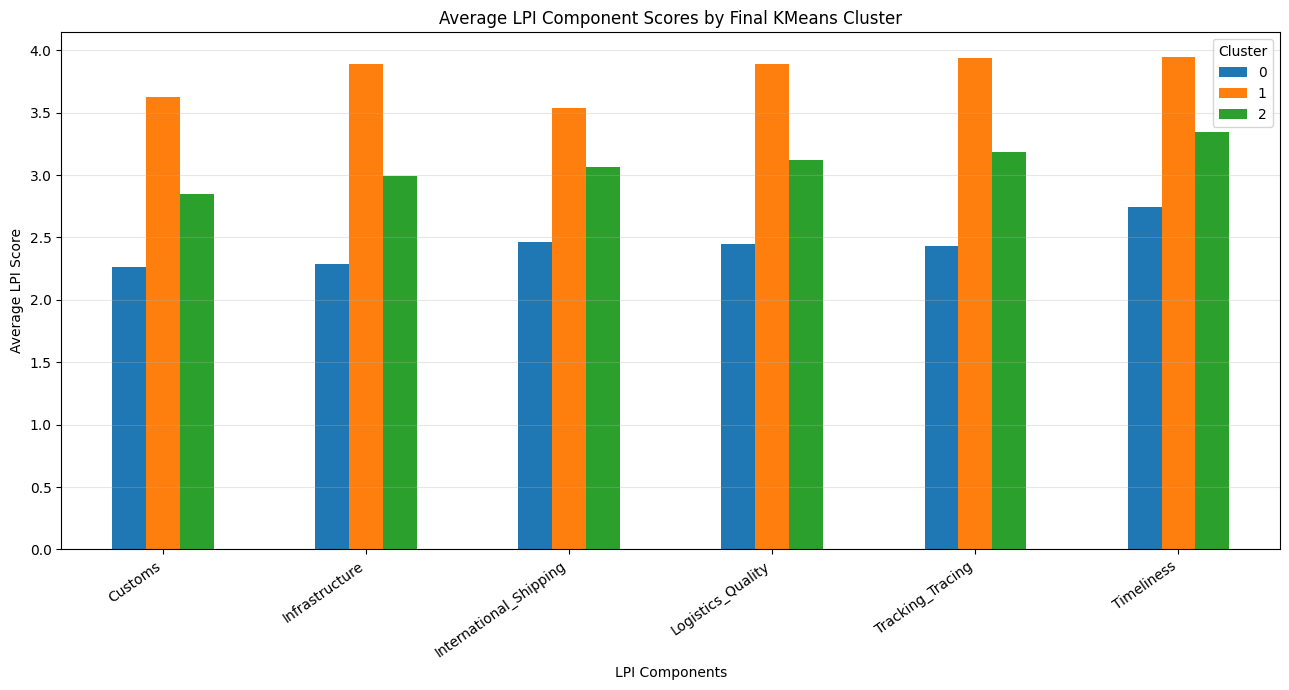

In [114]:
final_profiles.T.plot(
    kind="bar",
    figsize=(13, 7)
)

plt.title("Average LPI Component Scores by Final KMeans Cluster")
plt.xlabel("LPI Components")
plt.ylabel("Average LPI Score")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Cluster")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# **14. Comparaison économique des segmentations K=2 et K=3**

Cette étape vise à comparer les deux segmentations obtenues avec KMeans afin d'évaluer leur intérêt pour l'analyse de la performance logistique des pays.

La solution K=2 présente de meilleurs résultats selon les critères statistiques de validation. Toutefois, la segmentation K=3 permet de distinguer trois niveaux de performance logistique : faible, intermédiaire et élevé.

Cette comparaison permet ainsi de déterminer quelle configuration répond le mieux à l'objectif économique de notre étude, qui consiste à analyser les disparités logistiques entre les pays.

## **14.1. Modèle KMeans avec K=3**

In [115]:
# Entraîner KMeans avec K=2 comme modèle de comparaison
kmeans_2_reference = KMeans(
    n_clusters=2,
    random_state=SEED,
    n_init=30
)

labels_kmeans_2 = kmeans_2_reference.fit_predict(X_scaled_df)

# Calculer les profils moyens de K=2
X_k2 = X.copy()
X_k2["Cluster"] = labels_kmeans_2

profiles_k2 = (
    X_k2.groupby("Cluster")[feature_columns]
    .mean()
)

print("Profils moyens avec K=2 :")
display(profiles_k2.round(3))

print("Répartition des pays avec K=2 :")
display(
    pd.Series(labels_kmeans_2)
    .value_counts()
    .sort_index()
)

Profils moyens avec K=2 :


,Customs,Infrastructure,International_Shipping,Logistics_Quality,Tracking_Tracing,Timeliness
Cluster,,,,,,
0,2.346,2.373,2.554,2.547,2.567,2.851
1,3.398,3.643,3.413,3.663,3.688,3.758


Répartition des pays avec K=2 :


,count
0,79
1,60


## **14.2. Comparaison économique entre K=2 et K=3**

In [116]:
# Définir profiles_k3 à partir des profils finaux à 3 clusters
profiles_k3 = final_profiles

# Comparer les profils moyens des deux modèles
comparison_k2_k3 = pd.concat(
    {
        "KMeans K=2": profiles_k2,
        "KMeans K=3": profiles_k3
    },
    names=["Model", "Cluster"]
)

display(comparison_k2_k3.round(3))

Customs  Infrastructure  International_Shipping  \
Model      Cluster                                                    
KMeans K=2 0          2.346           2.373                   2.554   
           1          3.398           3.643                   3.413   
KMeans K=3 0          2.264           2.284                   2.464   
           1          3.627           3.892                   3.535   
           2          2.851           2.995                   3.061   

                    Logistics_Quality  Tracking_Tracing  Timeliness  
Model      Cluster                                                   
KMeans K=2 0                    2.547             2.567       2.851  
           1                    3.663             3.688       3.758  
KMeans K=3 0                    2.446             2.428       2.746  
           1                    3.889             3.935       3.946  
           2                    3.120             3.180       3.346

**Interprétation de la comparaison**

La segmentation en deux clusters distingue principalement les pays selon deux niveaux généraux de performance logistique : relativement faible et relativement élevé.

En revanche, la segmentation en trois clusters permet d'identifier un groupe intermédiaire dont les performances se situent entre les deux autres groupes.

Cette distinction apporte une information économique supplémentaire, car elle permet de mieux représenter les disparités de performance logistique entre les pays à l'échelle internationale.

Ainsi, bien que K=2 présente une meilleure séparation statistique, K=3 répond davantage à l'objectif de segmentation économique poursuivi dans cette étude.

# **15. Visualisation finale avec l’ACP**


## **15.1. Projection finale des clusters**

Figure saved: figure_12.png


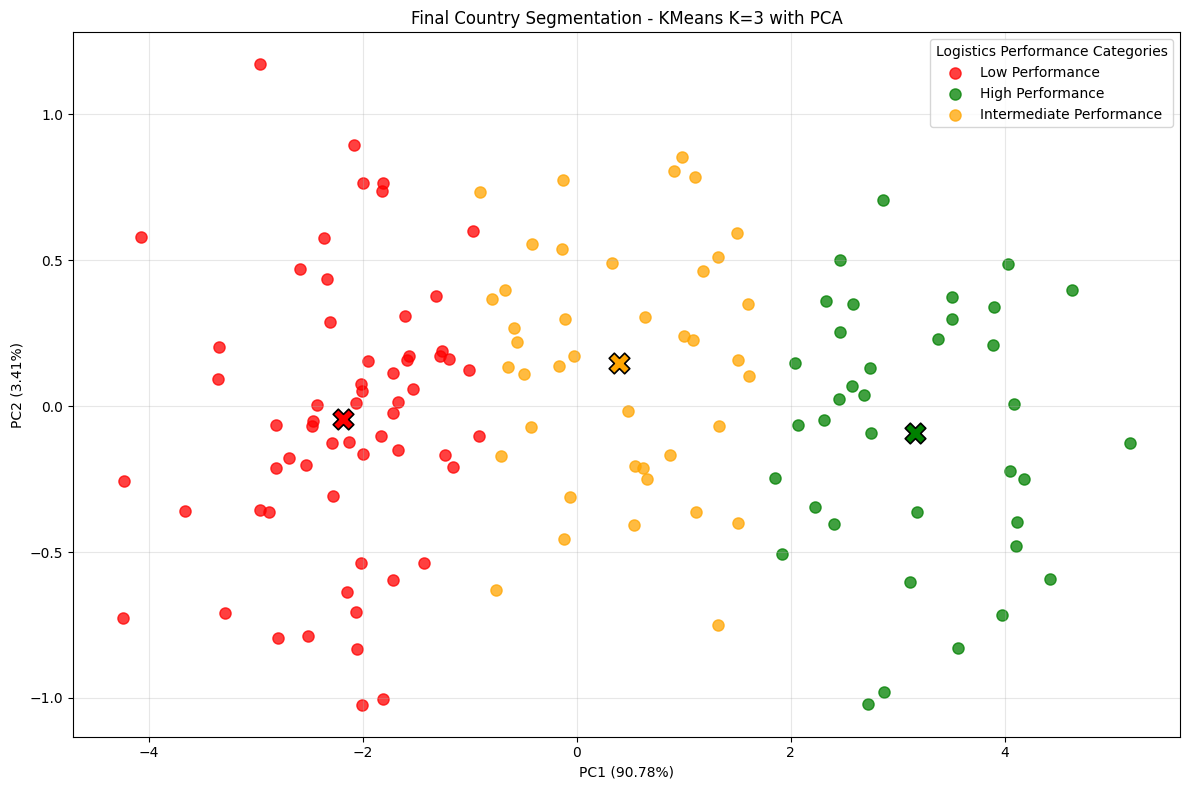

In [117]:
# Calculer le score moyen de chaque cluster
cluster_average_scores = final_profiles[feature_columns].mean(axis=1)

# Classer les clusters du plus faible au plus élevé
ordered_clusters = cluster_average_scores.sort_values().index.tolist()

# Associer les catégories économiques
cluster_categories = {
    ordered_clusters[0]: "Low Performance",
    ordered_clusters[1]: "Intermediate Performance",
    ordered_clusters[2]: "High Performance"
}

# Créer la visualisation PCA
plt.figure(figsize=(12, 8))

colors = {
    "Low Performance": "red",
    "Intermediate Performance": "orange",
    "High Performance": "green"
}

for cluster in sorted(np.unique(final_labels)):

    mask = final_labels == cluster
    category = cluster_categories[cluster]

    plt.scatter(
        pca_df.loc[mask, "PC1"],
        pca_df.loc[mask, "PC2"],
        s=65,
        alpha=0.75,
        color=colors[category],
        label=category
    )

# Projeter les centres des clusters dans l'espace PCA
final_centers_pca = pca.transform(
    final_kmeans.cluster_centers_
)

for cluster in range(FINAL_K):

    category = cluster_categories[cluster]

    plt.scatter(
        final_centers_pca[cluster, 0],
        final_centers_pca[cluster, 1],
        marker="X",
        s=220,
        color=colors[category],
        edgecolor="black",
        linewidth=1.2
    )

plt.xlabel(
    f"PC1 ({pca_variance.iloc[0]['Explained Variance (%)']:.2f}%)"
)

plt.ylabel(
    f"PC2 ({pca_variance.iloc[1]['Explained Variance (%)']:.2f}%)"
)

plt.title("Final Country Segmentation - KMeans K=3 with PCA")
plt.legend(title="Logistics Performance Categories")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **15.2. Visualisation des profils avec une heatmap**

Figure saved: figure_13.png


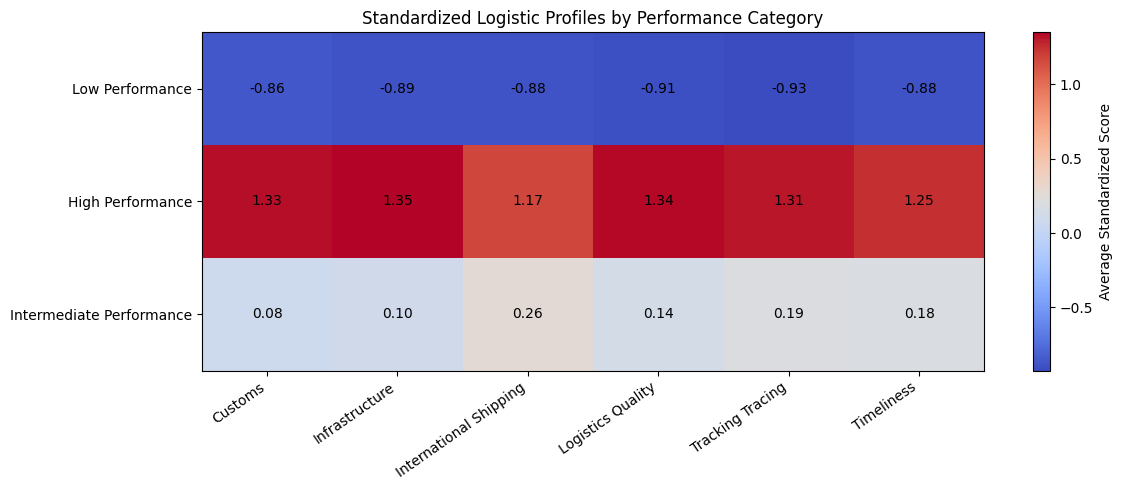

In [118]:
# Préparer les données standardisées
X_final_scaled = pd.DataFrame(
    X_scaled_df,
    columns=feature_columns
)

X_final_scaled["Cluster"] = final_labels

# Calculer les profils standardisés
standardized_profiles = (
    X_final_scaled
    .groupby("Cluster")[feature_columns]
    .mean()
)

# Remplacer les numéros par les catégories
standardized_profiles.index = [
    cluster_categories[cluster]
    for cluster in standardized_profiles.index
]

# Visualiser la heatmap
plt.figure(figsize=(12, 5))

image = plt.imshow(
    standardized_profiles,
    cmap="coolwarm",
    aspect="auto"
)

plt.colorbar(
    image,
    label="Average Standardized Score"
)

plt.xticks(
    range(len(feature_columns)),
    [col.replace("_", " ") for col in feature_columns],
    rotation=35,
    ha="right"
)

plt.yticks(
    range(len(standardized_profiles)),
    standardized_profiles.index
)

plt.title("Standardized Logistic Profiles by Performance Category")

for i in range(standardized_profiles.shape[0]):
    for j in range(standardized_profiles.shape[1]):
        plt.text(
            j,
            i,
            f"{standardized_profiles.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

# **16. Interprétation économique des clusters**

## **16.1. Interprétation économique des trois catégories de pays**

À la suite de l'application du modèle KMeans avec trois clusters, les 139 pays étudiés sont répartis en trois catégories selon leurs niveaux de performance logistique.

L'analyse des scores moyens des six composantes du LPI permet de distinguer les groupes suivants :

**Catégorie 1 : Pays à faible performance logistique**

Cette catégorie regroupe les pays présentant les scores moyens les plus faibles dans les six dimensions étudiées. Elle traduit des difficultés relativement importantes en matière de procédures douanières, d'infrastructures, de qualité des services logistiques, de suivi des expéditions et de ponctualité.

**Catégorie 2 : Pays à performance logistique intermédiaire**

Cette catégorie rassemble les pays dont les performances se situent entre les deux autres groupes. Ils présentent des résultats relativement meilleurs que ceux du groupe à faible performance, mais restent en retrait par rapport aux pays les plus performants.

**Catégorie 3 : Pays à performance logistique élevée**

Cette catégorie regroupe les pays obtenant les scores moyens les plus élevés dans les six composantes. Elle reflète des capacités logistiques relativement développées, favorisant la fluidité des échanges internationaux, la fiabilité des expéditions et la ponctualité des livraisons.

Cette classification permet ainsi de mieux comprendre les disparités de performance logistique entre les pays et de mettre en évidence trois niveaux de développement logistique à partir des données du LPI 2023.

## **16.2. Identification des pays appartenant à chaque catégorie**

Afin de rendre les résultats plus concrets, nous présentons la liste des pays appartenant à chacune des trois catégories identifiées par le modèle final.

Cette répartition permet d'identifier les pays composant chaque groupe et de mieux illustrer les différences de performance logistique observées à l'échelle internationale.

In [119]:
# Construire le tableau final des pays
country_cluster_results = country_info.reset_index(drop=True).copy()

country_cluster_results["Cluster"] = final_labels

# Ajouter les catégories économiques
country_cluster_results["Performance_Category"] = (
    country_cluster_results["Cluster"].map(cluster_categories)
)

# Définir l'ordre d'affichage des catégories
category_order = [
    "Low Performance",
    "Intermediate Performance",
    "High Performance"
]

# Afficher les pays de chaque catégorie
for category in category_order:

    category_countries = (
        country_cluster_results[
            country_cluster_results["Performance_Category"] == category
        ]
        .sort_values("Country")
        .reset_index(drop=True)
    )

    print("\n" + "=" * 60)
    print(category)
    print("Number of countries:", len(category_countries))
    print("=" * 60)

    display(
        category_countries[
            ["Country", "Country_Code"]
        ]
    )


Low Performance
Number of countries: 61


,Country,Country_Code
0,Afghanistan,AFG
1,Albania,ALB
2,Algeria,DZA
3,Angola,AGO
4,Armenia,ARM
5,"Bahamas, The",BHS
6,Bangladesh,BGD
7,Belarus,BLR
8,Bhutan,BTN
9,Bolivia,BOL



Intermediate Performance
Number of countries: 41


,Country,Country_Code
0,Antigua and Barbuda,ATG
1,Argentina,ARG
2,Benin,BEN
3,Bosnia and Herzegovina,BIH
4,Botswana,BWA
5,Brazil,BRA
6,Bulgaria,BGR
7,Chile,CHL
8,Colombia,COL
9,Costa Rica,CRI



High Performance
Number of countries: 37


,Country,Country_Code
0,Australia,AUS
1,Austria,AUT
2,Bahrain,BHR
3,Belgium,BEL
4,Canada,CAN
5,China,CHN
6,Denmark,DNK
7,Estonia,EST
8,Finland,FIN
9,France,FRA


## **16.3. Comparaison des profils logistiques des trois catégories**

Afin de compléter l'interprétation économique, nous comparons les scores moyens des six composantes du LPI pour chacune des trois catégories.

Cette comparaison permet d'identifier les dimensions dans lesquelles les groupes présentent les écarts les plus importants et de mieux comprendre leurs caractéristiques logistiques respectives.

In [120]:
# Calculer les profils moyens à partir des scores originaux
economic_profiles = final_profiles[feature_columns].copy()

# Remplacer les numéros de clusters par les catégories
economic_profiles.index = [
    cluster_categories[cluster]
    for cluster in economic_profiles.index
]

# Ajouter la moyenne générale des six composantes
economic_profiles["Average Score"] = (
    economic_profiles[feature_columns].mean(axis=1)
)

display(economic_profiles.round(3))

,Customs,Infrastructure,International_Shipping,Logistics_Quality,Tracking_Tracing,Timeliness,Average Score
Low Performance,2.264,2.284,2.464,2.446,2.428,2.746,2.439
High Performance,3.627,3.892,3.535,3.889,3.935,3.946,3.804
Intermediate Performance,2.851,2.995,3.061,3.120,3.180,3.346,3.092


## **16.4. Conclusion de l'interprétation économique**

L'analyse des trois catégories obtenues à l'aide de KMeans met en évidence des différences importantes entre les pays en matière de performance logistique.

La segmentation distingue les pays à faible performance, ceux présentant un niveau intermédiaire et ceux disposant des performances les plus élevées.

Cette classification permet d'obtenir une vision plus détaillée des disparités logistiques à l'échelle mondiale. Elle montre notamment que les différences entre les pays ne se limitent pas à une opposition entre deux niveaux de performance, mais peuvent également faire apparaître une catégorie intermédiaire.

Du point de vue du commerce international, ces différences peuvent influencer la fluidité des échanges, la fiabilité des chaînes d'approvisionnement, les délais de livraison et la compétitivité des pays.

Ainsi, le choix de trois clusters permet de proposer une segmentation économiquement plus informative, en cohérence avec l'objectif de notre étude.

# **17. Limites et conclusion générale**

## **17.1. Limites de l'étude**

Malgré les résultats obtenus, cette étude présente certaines limites.

Premièrement, l'analyse repose uniquement sur les données du LPI 2023. Elle fournit donc une photographie de la performance logistique des pays pour une période donnée et ne permet pas d'étudier son évolution dans le temps.

Deuxièmement, le nombre de pays étudiés est limité aux 139 pays disposant des observations nécessaires pour les six composantes sélectionnées.

Troisièmement, les résultats dépendent des variables retenues, de la méthode de standardisation et des paramètres des algorithmes de clustering. D'autres choix méthodologiques pourraient produire des segmentations différentes.

Enfin, les groupes obtenus représentent des proximités statistiques et ne doivent pas être interprétés comme des catégories économiques officielles de la Banque mondiale.

Ces limites doivent être prises en compte lors de l'interprétation des résultats et de leur utilisation dans le contexte du commerce international.

### **17.2. Conclusion générale**

Ce projet avait pour objectif d'identifier des groupes de pays présentant des caractéristiques similaires en matière de performance logistique, à partir des six composantes du Logistics Performance Index (LPI) 2023.

L'analyse exploratoire a mis en évidence des différences entre les pays ainsi que des corrélations positives importantes entre les différentes dimensions de la performance logistique.

L'analyse en composantes principales a ensuite montré que les deux premiers axes factoriels expliquent ensemble 94,19 % de la variance totale, permettant ainsi de représenter une grande partie de l'information initiale dans un espace à deux dimensions.

Plusieurs configurations de clustering ont été comparées à travers les méthodes KMeans et Agglomerative Clustering. Les résultats ont montré que la segmentation en deux clusters présentait les meilleures performances statistiques parmi les configurations étudiées.

Toutefois, compte tenu de l'objectif économique de notre projet, nous avons retenu KMeans avec trois clusters comme modèle final. Cette configuration permet de distinguer trois catégories de pays : ceux présentant une faible performance logistique, ceux ayant une performance intermédiaire et ceux disposant d'une performance élevée.

Cette segmentation offre une lecture plus détaillée des disparités logistiques entre les pays et permet de mieux comprendre les différences susceptibles d'influencer la fluidité des échanges internationaux, la fiabilité des chaînes d'approvisionnement et la compétitivité commerciale.

En définitive, ce projet montre l'intérêt des méthodes de clustering et de l'ACP pour analyser les profils logistiques des pays et mieux comprendre les écarts de performance dans le contexte du commerce international.

In [121]:

# ==========================================
# DOWNLOAD ALL PROJECT FIGURES
# ==========================================

import shutil
from google.colab import files
import os

# Check the exported figures
print("Number of exported figures:",
      len(os.listdir("/content/figures")))

# Create a ZIP archive
shutil.make_archive(
    "/content/LPI_Project_Figures",
    "zip",
    "/content/figures"
)

# Download the ZIP file
files.download("/content/LPI_Project_Figures.zip")


Number of exported figures: 13


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>